# Studi Kasus: Penerapan *Machine Learning* pada Sistem Analitik Cerdas Bank Digital "Nusantara Finance"

**Mata Kuliah:** Machine Learning
**Nama / NIM:** ____________________

---

Notebook ini berisi studi kasus beserta implementasi kode yang menerapkan seluruh konsep pada materi *Machine Learning*: pergeseran dari pemrograman berbasis aturan ke pendekatan berbasis data, alur kerja (*workflow*) ML, *Supervised Learning* (klasifikasi & regresi), *Unsupervised Learning* (*clustering*, reduksi dimensi, deteksi anomali, *association rule*), *Reinforcement Learning*, *Semi-Supervised Learning*, serta evaluasi model dan mitigasi *overfitting/underfitting*.

Seluruh kode dapat dijalankan langsung di **Google Colab** (menu *Runtime → Run all*) tanpa instalasi pustaka tambahan dan tanpa mengunggah file apa pun, karena data dibangkitkan di dalam notebook dengan *random seed* tetap sehingga hasilnya dapat direproduksi.

## Daftar Isi
1. Latar Belakang Studi Kasus
2. Permasalahan dan Tujuan
3. Persiapan Lingkungan
4. *Rule-Based Programming* vs *Machine Learning*
5. Tahap 1 — Pengumpulan Data (*Data Collection*)
6. Tahap 2 — Pra-pemrosesan Data (*Data Preprocessing*)
7. Tahap 3 — Pembagian Data (*Data Splitting*)
8. *Supervised Learning* — Klasifikasi Persetujuan Kredit
9. *Supervised Learning* — Regresi Estimasi Nilai Agunan Rumah (KPR)
10. *Unsupervised Learning* — *Clustering* Segmentasi Nasabah
11. *Unsupervised Learning* — Reduksi Dimensi (PCA & t-SNE)
12. *Unsupervised Learning* — Deteksi Anomali Transaksi (*Fraud Detection*)
13. *Unsupervised Learning* — *Association Rule Learning* untuk *Cross-Selling*
14. *Reinforcement Learning* — Navigasi Kendaraan Otonom Pengisi ATM
15. *Semi-Supervised Learning* — Kredit dengan Label Terbatas
16. Evaluasi Lanjutan: *Overfitting*, *Underfitting*, Validasi Silang, dan Analisis Residu
17. Ringkasan Hasil dan Kesimpulan

## 1. Latar Belakang Studi Kasus

**Nusantara Finance** (perusahaan fiktif) adalah bank digital yang melayani nasabah ritel di berbagai kota di Indonesia. Seiring bertambahnya jumlah nasabah, bank menghadapi beberapa masalah operasional yang selama ini ditangani dengan aturan manual (*if-else rules*) yang dirancang analis:

| No | Unit Bisnis | Masalah | Kondisi Saat Ini |
|---|---|---|---|
| 1 | Divisi Kredit | Ribuan pengajuan pinjaman per bulan harus diputuskan disetujui/ditolak | Aturan kaku: skor kredit ≥ 650, rasio cicilan ≤ 35%, tanpa tunggakan |
| 2 | Divisi KPR | Nilai agunan rumah harus ditaksir sebelum KPR dicairkan | Penaksiran manual oleh appraiser, lambat dan tidak konsisten |
| 3 | Divisi Pemasaran | Promosi dikirim seragam ke semua nasabah | Tidak ada segmentasi berbasis perilaku |
| 4 | Divisi Manajemen Risiko | Transaksi penipuan (*fraud*) sulit dikenali | Label *fraud* sangat sedikit sehingga aturan sulit dirancang |
| 5 | Divisi Produk | Penawaran produk tambahan (*cross-selling*) belum tepat sasaran | Tidak diketahui keterkaitan kepemilikan antarproduk |
| 6 | Divisi Operasional | Kendaraan pengisi uang ATM harus mencari rute terbaik di kota yang macet | Rute ditentukan pengemudi berdasarkan pengalaman |
| 7 | Divisi Kredit | Pelabelan data historis mahal karena butuh verifikasi analis | Hanya sebagian kecil data yang berlabel |

Studi kasus ini membangun solusi *machine learning* untuk ketujuh masalah tersebut. Karena data nasabah perbankan bersifat rahasia, data yang digunakan adalah **data simulasi** yang dibangkitkan dengan pola menyerupai kondisi nyata, termasuk "kotoran data" seperti nilai hilang, duplikasi, salah ketik, dan nilai tidak valid.

## 2. Permasalahan dan Tujuan

**Permasalahan** yang diselesaikan dan **jenis pembelajaran** yang sesuai:

| Masalah | Jenis Tugas ML | Algoritma yang Diterapkan |
|---|---|---|
| Persetujuan kredit (disetujui/ditolak) | *Supervised* — Klasifikasi | Logistic Regression, Decision Tree, Random Forest, SVM, KNN |
| Estimasi nilai agunan rumah | *Supervised* — Regresi | Linear Regression, Polynomial Regression, SVR |
| Segmentasi nasabah | *Unsupervised* — Clustering | K-Means, Hierarchical Clustering |
| Penyederhanaan & visualisasi fitur nasabah | *Unsupervised* — Reduksi Dimensi | PCA, t-SNE |
| Deteksi transaksi mencurigakan | *Unsupervised* — Anomaly Detection | Isolation Forest, One-Class SVM |
| Rekomendasi *cross-selling* produk | *Unsupervised* — Association Rule | Apriori (implementasi manual) |
| Rute kendaraan pengisi ATM | *Reinforcement Learning* | Q-Learning |
| Kredit dengan label terbatas | *Semi-Supervised Learning* | Self-Training, Label Spreading |

**Tujuan** studi kasus:
1. Menerapkan alur kerja ML secara lengkap: pengumpulan data → pra-pemrosesan → pembagian data → pelatihan → evaluasi.
2. Membandingkan pendekatan berbasis aturan dengan pendekatan berbasis data pada kasus persetujuan kredit.
3. Menerapkan dan membandingkan algoritma dari setiap kategori ML.
4. Mengevaluasi model dengan metrik yang tepat serta mendeteksi *overfitting* dan *underfitting*.

## 3. Persiapan Lingkungan

Seluruh pustaka berikut sudah tersedia secara bawaan di Google Colab. *Random seed* ditetapkan agar hasil dapat direproduksi.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

# Pra-pemrosesan & pembagian data
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_validate, GridSearchCV, learning_curve)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline

# Model supervised
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC, SVR, OneClassSVM
from sklearn.neighbors import KNeighborsClassifier

# Model unsupervised & semi-supervised
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.semi_supervised import SelfTrainingClassifier, LabelSpreading
from scipy.cluster.hierarchy import dendrogram, linkage

# Metrik evaluasi
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, adjusted_rand_score)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

# Wadah untuk merangkum hasil semua eksperimen di akhir notebook
RINGKASAN = {}
print('Semua pustaka berhasil dimuat.')

Semua pustaka berhasil dimuat.


## 4. *Rule-Based Programming* vs *Machine Learning*

Pada **pemrograman konvensional**, manusia menulis aturan secara eksplisit:

```
Data + Aturan (dibuat manusia)  ──►  Program  ──►  Keluaran
```

Pada **machine learning**, alurnya dibalik. Komputer diberikan data beserta contoh keluaran historis, lalu algoritma mempelajari polanya sendiri:

```
Data + Keluaran historis  ──►  Algoritma ML  ──►  Aturan / Model
Data baru + Model         ──►  Prediksi
```

Pada kasus Nusantara Finance, analis kredit selama ini memakai aturan berikut:

```python
if skor_kredit >= 650 and rasio_cicilan <= 0.35 and riwayat_tunggakan == 0:
    keputusan = 'Disetujui'
else:
    keputusan = 'Ditolak'
```

Aturan ini mudah dipahami, tetapi memiliki kelemahan: (1) ambang batasnya ditentukan secara subjektif, (2) tidak mempertimbangkan interaksi antarfaktor (misalnya nasabah dengan pendapatan sangat tinggi tetapi pernah menunggak sekali), dan (3) harus diperbarui manual ketika pola risiko berubah. Pada Bagian 8, aturan ini dijadikan **baseline** dan dibandingkan langsung dengan model *machine learning* pada data uji yang sama.

Hubungan bidang-bidangnya: **Artificial Intelligence ⊃ Machine Learning ⊃ Deep Learning**. Studi kasus ini berfokus pada algoritma *machine learning* klasik yang sesuai untuk data tabular perbankan.

## 5. Tahap 1 — Pengumpulan Data (*Data Collection*)

Dalam praktik, data pengajuan kredit dikumpulkan dari pangkalan data internal bank (data nasabah dan riwayat pinjaman), API biro kredit (skor kredit dan riwayat tunggakan), serta formulir aplikasi daring. Pada studi kasus ini, proses tersebut disimulasikan dengan membangkitkan **3.000 data pengajuan kredit** beserta keputusan historisnya.

Agar menyerupai data mentah sungguhan, data sengaja diberi masalah kualitas:
- nilai hilang (*missing values*) ±5% pada beberapa kolom,
- baris duplikat akibat pengajuan yang tersimpan dua kali,
- penulisan kategori yang tidak seragam (huruf kecil/besar, spasi berlebih),
- nilai usia yang tidak valid akibat salah input.

In [2]:
rng = np.random.default_rng(SEED)
N = 3000

# ---------- Atribut demografis & pekerjaan ----------
usia = rng.integers(21, 61, N)
pekerjaan = rng.choice(['PNS', 'Karyawan Swasta', 'Wiraswasta', 'Freelancer'], N, p=[0.20, 0.45, 0.20, 0.15])
pendapatan_dasar = {'PNS': 8, 'Karyawan Swasta': 9, 'Wiraswasta': 12, 'Freelancer': 7}   # juta rupiah/bulan
pendapatan = np.array([rng.lognormal(np.log(pendapatan_dasar[p]), 0.45) for p in pekerjaan]).round(2)
lama_bekerja = np.clip((usia - 21) * rng.uniform(0.2, 0.9, N), 0, None).round(1)
jumlah_tanggungan = rng.poisson(1.5, N).clip(0, 6)
status_pernikahan = rng.choice(['Lajang', 'Menikah', 'Cerai'], N, p=[0.35, 0.58, 0.07])
kepemilikan_rumah = rng.choice(['Milik Sendiri', 'Sewa', 'Keluarga'], N, p=[0.40, 0.35, 0.25])
kota = rng.choice(['Jakarta', 'Bandung', 'Surabaya', 'Medan', 'Makassar', 'Semarang'], N)

# ---------- Atribut kredit (dari biro kredit) ----------
riwayat_tunggakan = rng.poisson(0.6, N).clip(0, 6)
skor_kredit = (rng.normal(680, 70, N) - 35 * riwayat_tunggakan + 2 * lama_bekerja).clip(300, 850).round()

# ---------- Atribut pengajuan ----------
jumlah_pinjaman = (pendapatan * rng.uniform(2, 14, N)).round(1)          # juta rupiah
tenor_bulan = rng.choice([12, 24, 36, 48, 60], N)
cicilan = jumlah_pinjaman * (1 + 0.11 * tenor_bulan / 12) / tenor_bulan  # bunga flat 11%/tahun
dsr = cicilan / pendapatan                                                # debt service ratio

# ---------- Keputusan historis analis senior (label) ----------
logit = (-0.2 + 0.013 * (skor_kredit - 650) - 7.0 * (dsr - 0.30) - 0.55 * riwayat_tunggakan
         + 0.04 * lama_bekerja + 0.45 * (kepemilikan_rumah == 'Milik Sendiri')
         + 0.35 * (pekerjaan == 'PNS') - 0.45 * (pekerjaan == 'Freelancer')
         - 0.15 * jumlah_tanggungan - 0.7 * (usia > 55) + 0.6 * (pendapatan > 15)
         + 0.4 * (riwayat_tunggakan > 0) * (pendapatan > 12))
prob_setuju = 1 / (1 + np.exp(-logit))
disetujui = (rng.random(N) < prob_setuju).astype(int)

df_raw = pd.DataFrame({
    'id_pengajuan': [f'APP{i:05d}' for i in range(1, N + 1)],
    'usia': usia.astype(float), 'pekerjaan': pekerjaan, 'pendapatan_bulanan': pendapatan,
    'lama_bekerja_tahun': lama_bekerja, 'jumlah_tanggungan': jumlah_tanggungan,
    'status_pernikahan': status_pernikahan, 'kepemilikan_rumah': kepemilikan_rumah, 'kota': kota,
    'skor_kredit': skor_kredit, 'riwayat_tunggakan': riwayat_tunggakan,
    'jumlah_pinjaman': jumlah_pinjaman, 'tenor_bulan': tenor_bulan, 'disetujui': disetujui,
})

# ---------- Simulasi masalah kualitas data ----------
for kolom in ['pendapatan_bulanan', 'skor_kredit', 'lama_bekerja_tahun', 'pekerjaan', 'status_pernikahan']:
    idx = rng.choice(N, int(0.05 * N), replace=False)
    df_raw.loc[idx, kolom] = np.nan
idx_typo = rng.choice(N, 120, replace=False)
df_raw.loc[idx_typo, 'pekerjaan'] = df_raw.loc[idx_typo, 'pekerjaan'].map(
    lambda x: (x.lower() + '  ') if isinstance(x, str) else x)
idx_invalid = rng.choice(N, 12, replace=False)
df_raw.loc[idx_invalid, 'usia'] = rng.choice([-1, 0, 150, 999], 12)
df_raw = pd.concat([df_raw, df_raw.sample(60, random_state=SEED)], ignore_index=True)   # duplikat
df_raw = df_raw.sample(frac=1, random_state=SEED).reset_index(drop=True)

# Menyimpan seolah-olah hasil ekspor dari sistem, lalu membacanya kembali
df_raw.to_csv('data_pengajuan_kredit.csv', index=False)
df = pd.read_csv('data_pengajuan_kredit.csv')
print(f'Jumlah baris: {df.shape[0]:,} | Jumlah kolom: {df.shape[1]}')
display(df.head(8))

Jumlah baris: 3,060 | Jumlah kolom: 14


,id_pengajuan,usia,pekerjaan,pendapatan_bulanan,lama_bekerja_tahun,jumlah_tanggungan,status_pernikahan,kepemilikan_rumah,kota,skor_kredit,riwayat_tunggakan,jumlah_pinjaman,tenor_bulan,disetujui
0,APP01765,44.000,NaN,10.240,11.000,2,Lajang,Sewa,Jakarta,631.000,1,85.300,48,1
1,APP00204,48.000,Karyawan Swasta,21.070,23.600,1,Menikah,Keluarga,Jakarta,671.000,0,160.900,36,1
2,APP01357,34.000,Wiraswasta,19.840,6.600,2,Lajang,Keluarga,Semarang,602.000,1,136.700,24,1
3,APP01452,22.000,Wiraswasta,23.000,0.800,2,Lajang,Milik Sendiri,Jakarta,568.000,2,169.100,48,1
4,APP01578,52.000,Karyawan Swasta,8.800,15.000,2,Lajang,Sewa,Makassar,756.000,0,98.900,12,0
5,APP00103,53.000,Wiraswasta,13.370,NaN,2,Menikah,Sewa,Medan,574.000,0,104.700,48,0
6,APP02839,29.000,Karyawan Swasta,10.680,2.600,2,Menikah,Keluarga,Surabaya,492.000,0,58.900,48,0
7,APP01819,26.000,PNS,11.270,3.300,1,Menikah,Milik Sendiri,Surabaya,593.000,1,118.500,12,0


In [3]:
print('Informasi tipe data:')
df.info()
print('\nStatistik deskriptif kolom numerik:')
display(df.describe().T)

Informasi tipe data:
<class 'pandas.DataFrame'>
RangeIndex: 3060 entries, 0 to 3059
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pengajuan        3060 non-null   str    
 1   usia                3060 non-null   float64
 2   pekerjaan           2905 non-null   str    
 3   pendapatan_bulanan  2910 non-null   float64
 4   lama_bekerja_tahun  2908 non-null   float64
 5   jumlah_tanggungan   3060 non-null   int64  
 6   status_pernikahan   2910 non-null   str    
 7   kepemilikan_rumah   3060 non-null   str    
 8   kota                3060 non-null   str    
 9   skor_kredit         2908 non-null   float64
 10  riwayat_tunggakan   3060 non-null   int64  
 11  jumlah_pinjaman     3060 non-null   float64
 12  tenor_bulan         3060 non-null   int64  
 13  disetujui           3060 non-null   int64  
dtypes: float64(5), int64(4), str(5)
memory usage: 334.8 KB

Statistik deskriptif kolom numerik:


,count,mean,std,min,25%,50%,75%,max
usia,"3,060.000",42.141,40.528,-1.000,31.000,41.000,51.000,999.000
pendapatan_bulanan,"2,910.000",10.180,5.326,1.250,6.570,8.880,12.438,50.830
lama_bekerja_tahun,"2,908.000",10.804,7.875,0.000,4.375,9.400,15.900,34.400
jumlah_tanggungan,"3,060.000",1.507,1.221,0.000,1.000,1.000,2.000,6.000
skor_kredit,"2,908.000",680.384,77.018,386.000,631.000,682.000,731.000,850.000
riwayat_tunggakan,"3,060.000",0.607,0.783,0.000,0.000,0.000,1.000,6.000
jumlah_pinjaman,"3,060.000",80.753,57.104,5.100,39.900,66.750,105.925,503.100
tenor_bulan,"3,060.000",36.259,16.913,12.000,24.000,36.000,48.000,60.000
disetujui,"3,060.000",0.500,0.500,0.000,0.000,0.000,1.000,1.000


## 6. Tahap 2 — Pra-pemrosesan Data (*Data Preprocessing*)

### 6.1 Audit kualitas data
Sebelum data dibersihkan, masalah kualitasnya diidentifikasi terlebih dahulu.

Nilai hilang per kolom:


,jumlah_missing,persen_missing
pekerjaan,155,5.070
pendapatan_bulanan,150,4.900
lama_bekerja_tahun,152,4.970
status_pernikahan,150,4.900
skor_kredit,152,4.970


Jumlah baris duplikat (berdasarkan id_pengajuan): 60
Jumlah usia tidak valid (<17 atau >80): 12

Variasi penulisan kolom pekerjaan:
pekerjaan
Karyawan Swasta      1263
PNS                   573
Wiraswasta            542
Freelancer            407
NaN                   155
karyawan swasta        61
wiraswasta             27
freelancer             19
pns                    13


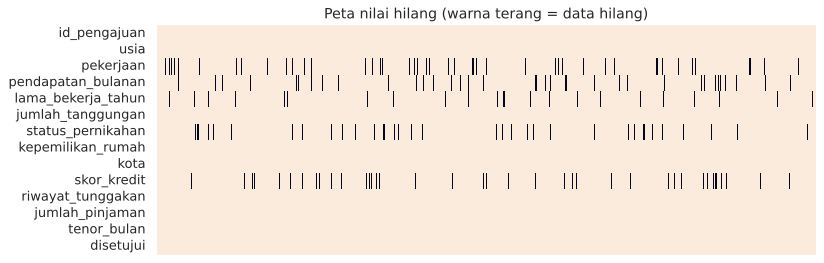

In [4]:
audit = pd.DataFrame({
    'jumlah_missing': df.isna().sum(),
    'persen_missing': (df.isna().mean() * 100).round(2),
})
print('Nilai hilang per kolom:')
display(audit[audit['jumlah_missing'] > 0])

print(f"Jumlah baris duplikat (berdasarkan id_pengajuan): {df.duplicated('id_pengajuan').sum()}")
print(f"Jumlah usia tidak valid (<17 atau >80): {((df['usia'] < 17) | (df['usia'] > 80)).sum()}")
print('\nVariasi penulisan kolom pekerjaan:')
print(df['pekerjaan'].value_counts(dropna=False).to_string())

fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(df.isna().T, cbar=False, cmap='rocket_r', ax=ax)
ax.set_title('Peta nilai hilang (warna terang = data hilang)')
ax.set_xticks([])
plt.show()

### 6.2 Pembersihan data
Langkah pembersihan yang dilakukan:
1. **Menghapus duplikat** berdasarkan `id_pengajuan`.
2. **Menyeragamkan kategori** pada kolom `pekerjaan` (menghapus spasi, menyamakan huruf).
3. **Mengubah nilai tidak valid** pada `usia` menjadi nilai hilang agar diimputasi bersama nilai hilang lainnya.
4. **Rekayasa fitur** (*feature engineering*): menghitung `cicilan_bulanan` dan `rasio_cicilan` (*Debt Service Ratio*), yaitu proporsi pendapatan yang terpakai untuk cicilan. Fitur ini lazim dipakai analis kredit.

In [5]:
df_clean = df.copy()

# 1) Hapus duplikat
sebelum = len(df_clean)
df_clean = df_clean.drop_duplicates(subset='id_pengajuan').reset_index(drop=True)
print(f'Duplikat dihapus: {sebelum - len(df_clean)} baris -> sisa {len(df_clean):,} baris')

# 2) Seragamkan kategori pekerjaan
peta_pekerjaan = {'pns': 'PNS', 'karyawan swasta': 'Karyawan Swasta',
                  'wiraswasta': 'Wiraswasta', 'freelancer': 'Freelancer'}
df_clean['pekerjaan'] = df_clean['pekerjaan'].str.strip().str.lower().map(peta_pekerjaan)
print('\nKategori pekerjaan setelah diseragamkan:')
print(df_clean['pekerjaan'].value_counts(dropna=False).to_string())

# 3) Nilai usia tidak valid -> NaN
df_clean.loc[(df_clean['usia'] < 17) | (df_clean['usia'] > 80), 'usia'] = np.nan

# 4) Rekayasa fitur
df_clean['cicilan_bulanan'] = (df_clean['jumlah_pinjaman'] * (1 + 0.11 * df_clean['tenor_bulan'] / 12)
                               / df_clean['tenor_bulan'])
df_clean['rasio_cicilan'] = df_clean['cicilan_bulanan'] / df_clean['pendapatan_bulanan']

print(f"\nProporsi kelas target: disetujui = {df_clean['disetujui'].mean():.1%}, "
      f"ditolak = {1 - df_clean['disetujui'].mean():.1%}")

Duplikat dihapus: 60 baris -> sisa 3,000 baris

Kategori pekerjaan setelah diseragamkan:
pekerjaan
Karyawan Swasta    1299
PNS                 578
Wiraswasta          552
Freelancer          421
NaN                 150

Proporsi kelas target: disetujui = 50.1%, ditolak = 49.9%


### 6.3 Eksplorasi data (EDA) singkat

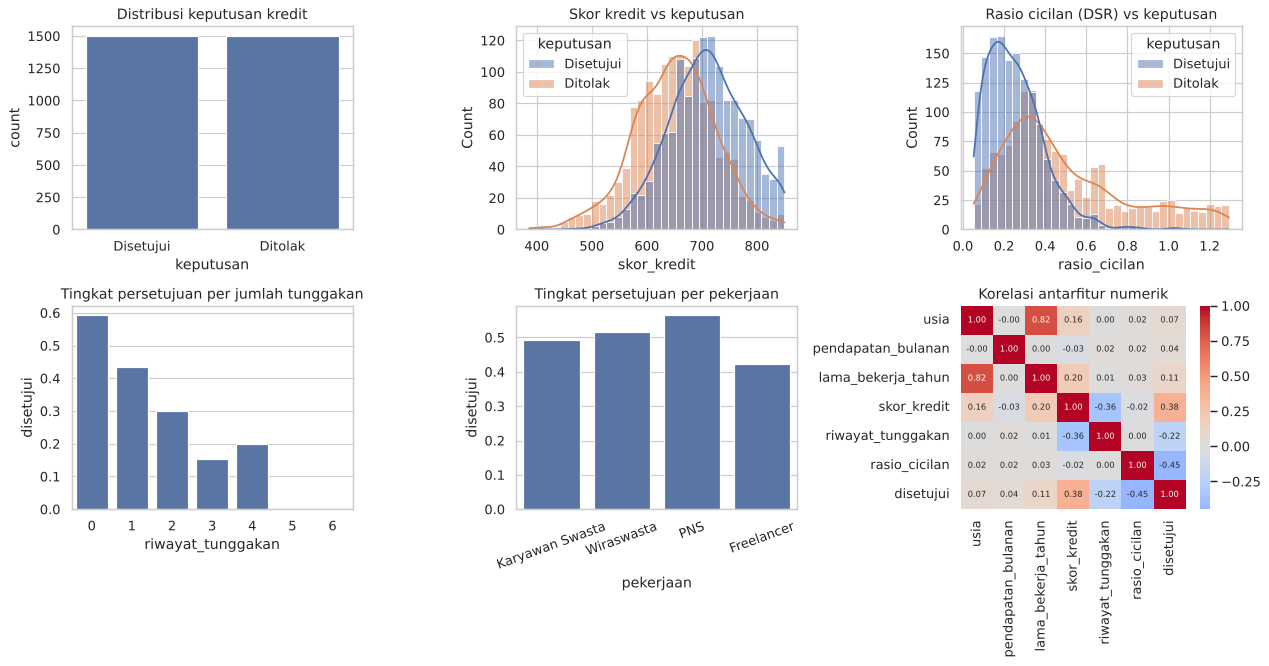

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
label_map = {0: 'Ditolak', 1: 'Disetujui'}
tmp = df_clean.assign(keputusan=df_clean['disetujui'].map(label_map))

sns.countplot(data=tmp, x='keputusan', ax=axes[0, 0])
axes[0, 0].set_title('Distribusi keputusan kredit')
sns.histplot(data=tmp, x='skor_kredit', hue='keputusan', kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Skor kredit vs keputusan')
sns.histplot(data=tmp[tmp['rasio_cicilan'] < 1.5], x='rasio_cicilan', hue='keputusan', kde=True, ax=axes[0, 2])
axes[0, 2].set_title('Rasio cicilan (DSR) vs keputusan')
sns.barplot(data=tmp, x='riwayat_tunggakan', y='disetujui', ax=axes[1, 0], errorbar=None)
axes[1, 0].set_title('Tingkat persetujuan per jumlah tunggakan')
sns.barplot(data=tmp, x='pekerjaan', y='disetujui', ax=axes[1, 1], errorbar=None)
axes[1, 1].set_title('Tingkat persetujuan per pekerjaan')
axes[1, 1].tick_params(axis='x', rotation=20)
num_cols = ['usia', 'pendapatan_bulanan', 'lama_bekerja_tahun', 'skor_kredit',
            'riwayat_tunggakan', 'rasio_cicilan', 'disetujui']
sns.heatmap(df_clean[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 2],
            annot_kws={'size': 7})
axes[1, 2].set_title('Korelasi antarfitur numerik')
plt.tight_layout()
plt.show()

### 6.4 Imputasi, *encoding*, dan normalisasi

Tiga transformasi berikut diperlukan sebelum data masuk ke algoritma:
- **Imputasi nilai hilang** — kolom numerik diisi median (tahan terhadap pencilan), kolom kategorik diisi modus.
- **Encoding** — kolom kategorik diubah menjadi vektor numerik dengan *One-Hot Encoding*.
- **Normalisasi/standardisasi** — rentang nilai fitur disamakan agar fitur bernilai besar (misalnya skor kredit 300–850) tidak mendominasi fitur bernilai kecil (misalnya jumlah tanggungan 0–6). Ini penting terutama bagi algoritma berbasis jarak (KNN, SVM).

Contoh efek normalisasi *Min-Max* dan standardisasi *Z-score*:

In [7]:
contoh = df_clean[['skor_kredit', 'pendapatan_bulanan', 'jumlah_tanggungan']].dropna().head(5)
minmax = pd.DataFrame(MinMaxScaler().fit(df_clean[contoh.columns].dropna()).transform(contoh),
                      columns=[c + '_minmax' for c in contoh.columns])
zscore = pd.DataFrame(StandardScaler().fit(df_clean[contoh.columns].dropna()).transform(contoh),
                      columns=[c + '_zscore' for c in contoh.columns])
display(pd.concat([contoh.reset_index(drop=True), minmax, zscore], axis=1).round(3))

print('Contoh One-Hot Encoding kolom kepemilikan_rumah:')
display(pd.get_dummies(df_clean['kepemilikan_rumah'].head(5), prefix='rumah').astype(int)
        .assign(asli=df_clean['kepemilikan_rumah'].head(5).values))

,skor_kredit,pendapatan_bulanan,jumlah_tanggungan,skor_kredit_minmax,pendapatan_bulanan_minmax,jumlah_tanggungan_minmax,skor_kredit_zscore,pendapatan_bulanan_zscore,jumlah_tanggungan_zscore
0,631.000,10.240,2,0.528,0.181,0.333,-0.647,0.012,0.403
1,671.000,21.070,1,0.614,0.400,0.167,-0.124,2.046,-0.413
2,602.000,19.840,2,0.466,0.375,0.333,-1.027,1.815,0.403
3,568.000,23.000,2,0.392,0.439,0.333,-1.472,2.408,0.403
4,756.000,8.800,2,0.797,0.152,0.333,0.988,-0.258,0.403


Contoh One-Hot Encoding kolom kepemilikan_rumah:


,rumah_Keluarga,rumah_Milik Sendiri,rumah_Sewa,asli
0,0,0,1,Sewa
1,1,0,0,Keluarga
2,1,0,0,Keluarga
3,0,1,0,Milik Sendiri
4,0,0,1,Sewa


Agar tidak terjadi **kebocoran data** (*data leakage*), nilai median, modus, rata-rata, dan simpangan baku untuk imputasi dan standardisasi **hanya dihitung dari data latih**, kemudian diterapkan ke data uji. Karena itu, transformasi tersebut dibungkus dalam `Pipeline` + `ColumnTransformer` yang baru di-*fit* setelah data dibagi.

In [8]:
fitur_numerik = ['usia', 'pendapatan_bulanan', 'lama_bekerja_tahun', 'jumlah_tanggungan', 'skor_kredit',
                 'riwayat_tunggakan', 'jumlah_pinjaman', 'tenor_bulan', 'rasio_cicilan']
fitur_kategorik = ['pekerjaan', 'status_pernikahan', 'kepemilikan_rumah', 'kota']

def buat_preprocessor():
    return ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), fitur_numerik),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]),
         fitur_kategorik),
    ])

print('Preprocessor siap:', buat_preprocessor())

Preprocessor siap: ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['usia', 'pendapatan_bulanan',
                                  'lama_bekerja_tahun', 'jumlah_tanggungan',
                                  'skor_kredit', 'riwayat_tunggakan',
                                  'jumlah_pinjaman', 'tenor_bulan',
                                  'rasio_cicilan']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                        

## 7. Tahap 3 — Pembagian Data (*Data Splitting*)

Data dibagi menjadi **80% data latih** dan **20% data uji** dengan *stratified split* agar proporsi kelas disetujui/ditolak sama pada kedua bagian. Data uji tidak disentuh selama pelatihan sehingga berperan sebagai *unseen data* untuk mengukur kemampuan generalisasi.

In [9]:
X = df_clean[fitur_numerik + fitur_kategorik]
y = df_clean['disetujui']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)

print(f'Data latih : {X_train.shape[0]:,} baris ({X_train.shape[0] / len(X):.0%})')
print(f'Data uji   : {X_test.shape[0]:,} baris ({X_test.shape[0] / len(X):.0%})')
print(f'Proporsi disetujui -> latih: {y_train.mean():.3f} | uji: {y_test.mean():.3f}')

Data latih : 2,400 baris (80%)
Data uji   : 600 baris (20%)
Proporsi disetujui -> latih: 0.501 | uji: 0.500


## 8. *Supervised Learning* — Klasifikasi Persetujuan Kredit

**Tujuan:** memprediksi apakah pengajuan kredit **disetujui (1)** atau **ditolak (0)**. Karena labelnya diskret dan tersedia dari keputusan historis, masalah ini termasuk *supervised learning* jenis klasifikasi.

### 8.1 Baseline: sistem berbasis aturan

In [10]:
def keputusan_rule_based(data):
    # Aturan manual analis kredit. Data yang hilang dianggap tidak memenuhi syarat.
    return ((data['skor_kredit'] >= 650) & (data['rasio_cicilan'] <= 0.35)
            & (data['riwayat_tunggakan'] == 0)).astype(int)

def hitung_metrik(y_true, y_pred, y_prob=None):
    hasil = {'Akurasi': accuracy_score(y_true, y_pred),
             'Presisi': precision_score(y_true, y_pred, zero_division=0),
             'Recall': recall_score(y_true, y_pred),
             'F1-Score': f1_score(y_true, y_pred)}
    hasil['ROC-AUC'] = roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan
    return hasil

pred_rule = keputusan_rule_based(X_test)
hasil_klasifikasi = {'Rule-Based (baseline)': hitung_metrik(y_test, pred_rule)}
print('Performa sistem berbasis aturan pada data uji:')
for k, v in hasil_klasifikasi['Rule-Based (baseline)'].items():
    if not np.isnan(v):
        print(f'  {k:<9}: {v:.4f}')

Performa sistem berbasis aturan pada data uji:
  Akurasi  : 0.6550
  Presisi  : 0.8207
  Recall   : 0.3967
  F1-Score : 0.5348


### 8.2 Pelatihan lima algoritma klasifikasi
Setiap algoritma digabungkan dengan *preprocessor* dalam satu `Pipeline`, sehingga proses imputasi–encoding–standardisasi–pelatihan berjalan konsisten.

| Algoritma | Prinsip Kerja Singkat |
|---|---|
| Logistic Regression | Model linear yang memetakan kombinasi fitur menjadi peluang melalui fungsi sigmoid |
| Decision Tree | Memecah data secara bertingkat berdasarkan aturan if-else yang dipelajari otomatis |
| Random Forest | Gabungan ratusan *decision tree* yang dilatih pada sampel acak, lalu hasilnya di-*voting* |
| Support Vector Machine | Mencari *hyperplane* pemisah dengan margin terlebar, dapat non-linear melalui kernel RBF |
| K-Nearest Neighbors | Mengklasifikasi berdasarkan mayoritas label dari *k* tetangga terdekat |

In [11]:
model_klasifikasi = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=SEED),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
    'SVM (RBF)': SVC(kernel='rbf', C=1.0, probability=True, random_state=SEED),
    'KNN (k=15)': KNeighborsClassifier(n_neighbors=15),
}

pipeline_terlatih = {}
for nama, model in model_klasifikasi.items():
    pipe = Pipeline([('prep', buat_preprocessor()), ('model', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    hasil_klasifikasi[nama] = hitung_metrik(y_test, y_pred, y_prob)
    pipeline_terlatih[nama] = pipe
    print(f'{nama:<22} selesai dilatih')

tabel_klasifikasi = pd.DataFrame(hasil_klasifikasi).T.sort_values('F1-Score', ascending=False)
print('\nPerbandingan performa pada data uji:')
display(tabel_klasifikasi.round(4))

Logistic Regression    selesai dilatih
Decision Tree          selesai dilatih
Random Forest          selesai dilatih
SVM (RBF)              selesai dilatih
KNN (k=15)             selesai dilatih

Perbandingan performa pada data uji:


,Akurasi,Presisi,Recall,F1-Score,ROC-AUC
Logistic Regression,0.787,0.769,0.820,0.793,0.864
Random Forest,0.778,0.760,0.813,0.786,0.847
SVM (RBF),0.778,0.760,0.813,0.786,0.852
Decision Tree,0.730,0.705,0.790,0.745,0.803
KNN (k=15),0.723,0.695,0.797,0.742,0.810
Rule-Based (baseline),0.655,0.821,0.397,0.535,NaN


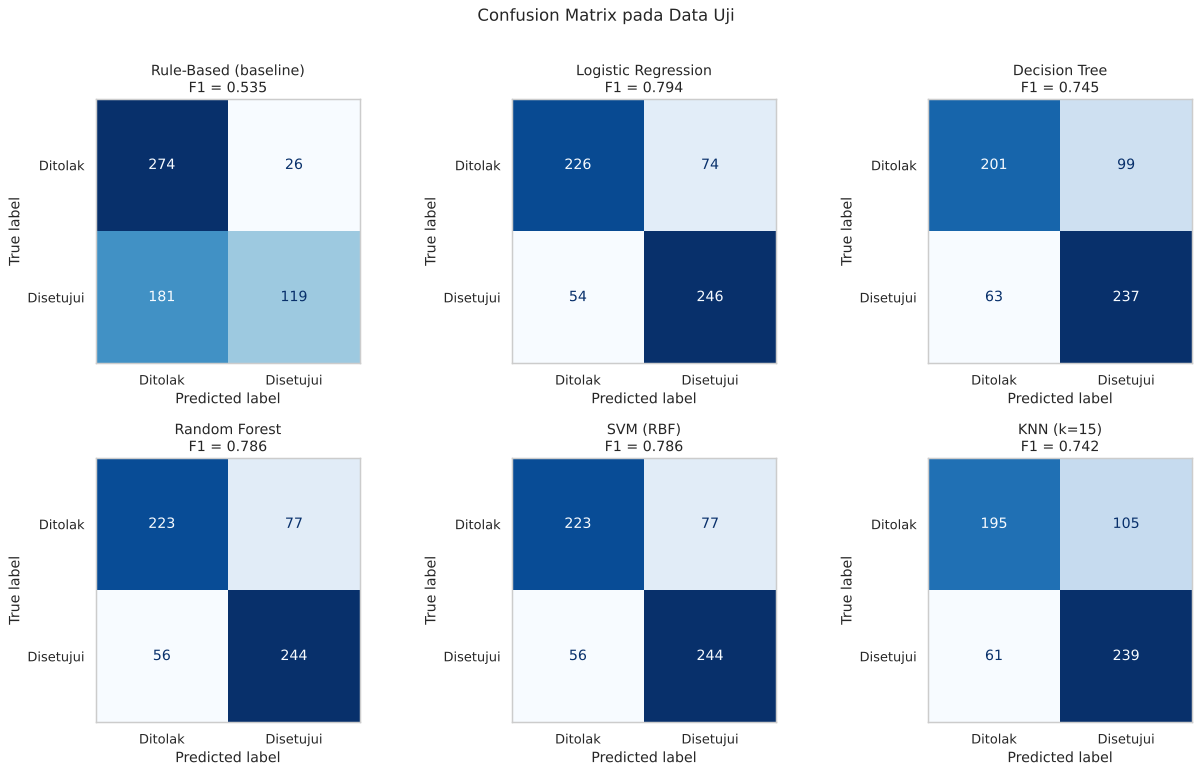

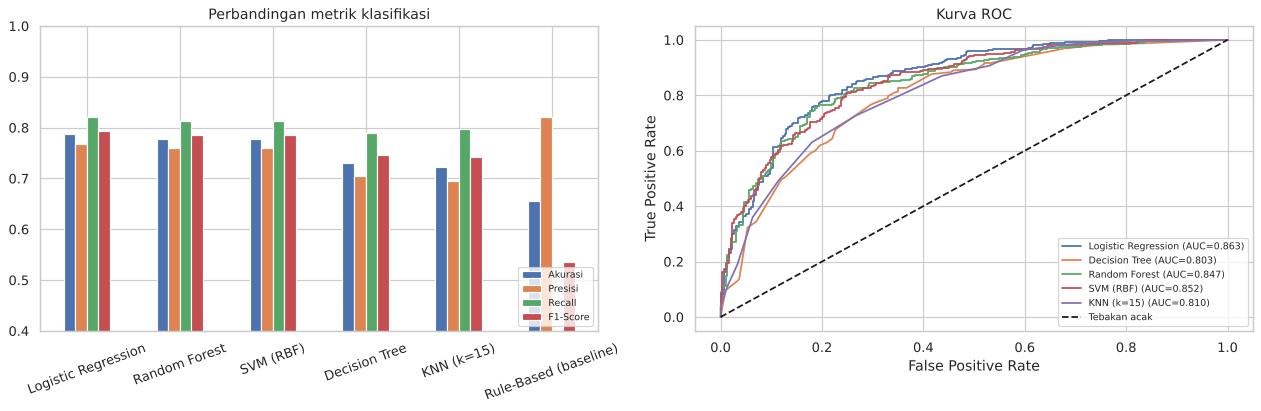

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
semua_prediksi = {'Rule-Based (baseline)': pred_rule}
semua_prediksi.update({n: p.predict(X_test) for n, p in pipeline_terlatih.items()})
for ax, (nama, pred) in zip(axes.ravel(), semua_prediksi.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Ditolak', 'Disetujui']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f"{nama}\nF1 = {f1_score(y_test, pred):.3f}")
    ax.grid(False)
plt.suptitle('Confusion Matrix pada Data Uji', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
tabel_klasifikasi.drop(columns='ROC-AUC').plot(kind='bar', ax=axes[0], rot=20)
axes[0].set_ylim(0.4, 1.0)
axes[0].set_title('Perbandingan metrik klasifikasi')
axes[0].legend(loc='lower right', fontsize=8)
for nama, pipe in pipeline_terlatih.items():
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    axes[1].plot(fpr, tpr, label=f"{nama} (AUC={hasil_klasifikasi[nama]['ROC-AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], 'k--', label='Tebakan acak')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Kurva ROC')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 8.3 Laporan klasifikasi model terbaik dan faktor paling berpengaruh

Model terbaik berdasarkan F1-Score: Logistic Regression

              precision    recall  f1-score   support

     Ditolak     0.8071    0.7533    0.7793       300
   Disetujui     0.7688    0.8200    0.7935       300

    accuracy                         0.7867       600
   macro avg     0.7879    0.7867    0.7864       600
weighted avg     0.7879    0.7867    0.7864       600



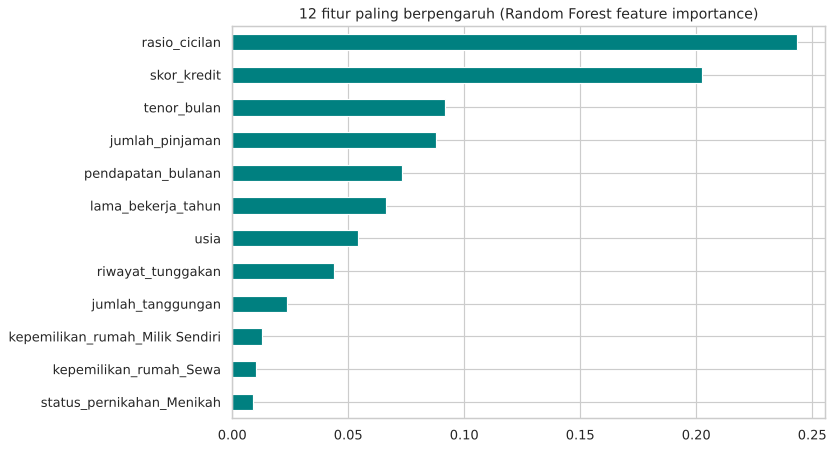

In [13]:
nama_terbaik = tabel_klasifikasi.drop(index='Rule-Based (baseline)')['F1-Score'].idxmax()
model_terbaik = pipeline_terlatih[nama_terbaik]
print(f'Model terbaik berdasarkan F1-Score: {nama_terbaik}\n')
print(classification_report(y_test, model_terbaik.predict(X_test), target_names=['Ditolak', 'Disetujui'], digits=4))

# Faktor paling berpengaruh menurut Random Forest
rf_pipe = pipeline_terlatih['Random Forest']
nama_fitur = rf_pipe.named_steps['prep'].get_feature_names_out()
nama_fitur = [n.split('__')[1] for n in nama_fitur]
importance = pd.Series(rf_pipe.named_steps['model'].feature_importances_, index=nama_fitur).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
importance.tail(12).plot(kind='barh', ax=ax, color='teal')
ax.set_title('12 fitur paling berpengaruh (Random Forest feature importance)')
plt.show()

RINGKASAN['Klasifikasi kredit'] = (f"{nama_terbaik}: F1={tabel_klasifikasi.loc[nama_terbaik, 'F1-Score']:.3f}, "
                                   f"Akurasi={tabel_klasifikasi.loc[nama_terbaik, 'Akurasi']:.3f} "
                                   f"(rule-based F1={tabel_klasifikasi.loc['Rule-Based (baseline)', 'F1-Score']:.3f})")

### 8.4 Simulasi penggunaan model untuk pengajuan baru
Model yang sudah dilatih dapat langsung dipakai untuk menilai pengajuan baru. Berikut tiga calon debitur dengan profil berbeda:

In [14]:
pengajuan_baru = pd.DataFrame([
    {'usia': 34, 'pekerjaan': 'PNS', 'pendapatan_bulanan': 11.0, 'lama_bekerja_tahun': 8,
     'jumlah_tanggungan': 2, 'status_pernikahan': 'Menikah', 'kepemilikan_rumah': 'Milik Sendiri',
     'kota': 'Bandung', 'skor_kredit': 735, 'riwayat_tunggakan': 0, 'jumlah_pinjaman': 60, 'tenor_bulan': 36},
    {'usia': 26, 'pekerjaan': 'Freelancer', 'pendapatan_bulanan': 5.5, 'lama_bekerja_tahun': 2,
     'jumlah_tanggungan': 1, 'status_pernikahan': 'Lajang', 'kepemilikan_rumah': 'Sewa',
     'kota': 'Jakarta', 'skor_kredit': 610, 'riwayat_tunggakan': 2, 'jumlah_pinjaman': 70, 'tenor_bulan': 24},
    {'usia': 45, 'pekerjaan': 'Wiraswasta', 'pendapatan_bulanan': 28.0, 'lama_bekerja_tahun': 15,
     'jumlah_tanggungan': 3, 'status_pernikahan': 'Menikah', 'kepemilikan_rumah': 'Milik Sendiri',
     'kota': 'Surabaya', 'skor_kredit': 640, 'riwayat_tunggakan': 1, 'jumlah_pinjaman': 150, 'tenor_bulan': 48},
])
pengajuan_baru['rasio_cicilan'] = (pengajuan_baru['jumlah_pinjaman'] * (1 + 0.11 * pengajuan_baru['tenor_bulan'] / 12)
                                   / pengajuan_baru['tenor_bulan'] / pengajuan_baru['pendapatan_bulanan'])

hasil_baru = pengajuan_baru[['pekerjaan', 'pendapatan_bulanan', 'skor_kredit', 'riwayat_tunggakan', 'rasio_cicilan']].copy()
hasil_baru['rule_based'] = keputusan_rule_based(pengajuan_baru).map(label_map)
hasil_baru[f'peluang_disetujui ({nama_terbaik})'] = model_terbaik.predict_proba(pengajuan_baru[X.columns])[:, 1].round(3)
hasil_baru['prediksi_ML'] = model_terbaik.predict(pengajuan_baru[X.columns])
hasil_baru['prediksi_ML'] = hasil_baru['prediksi_ML'].map(label_map)
display(hasil_baru)

,pekerjaan,pendapatan_bulanan,skor_kredit,riwayat_tunggakan,rasio_cicilan,rule_based,peluang_disetujui (Logistic Regression),prediksi_ML
0,PNS,11.000,735,0,0.202,Disetujui,0.931,Disetujui
1,Freelancer,5.500,610,2,0.647,Ditolak,0.014,Ditolak
2,Wiraswasta,28.000,640,1,0.161,Ditolak,0.840,Disetujui


### 8.5 Analisis hasil klasifikasi

1. **Sistem berbasis aturan terlalu konservatif.** Aturan manual hanya mencapai akurasi **65,5%** dan *recall* **39,7%**. Artinya, dari 300 pengajuan yang layak disetujui pada data uji, hanya sekitar 119 yang benar-benar disetujui; sisanya ditolak walaupun sebenarnya layak. Presisi aturan memang tinggi (82,1%), tetapi bank kehilangan banyak calon debitur yang baik.
2. **Model ML jauh lebih seimbang.** *Logistic Regression* menjadi model terbaik dengan akurasi **78,7%**, F1-score **0,794**, dan ROC-AUC **0,864**, disusul *Random Forest* dan *SVM* (F1 0,786). Dibanding aturan manual, F1-score naik dari 0,535 menjadi 0,794 karena *recall* meningkat menjadi 82%, dengan presisi yang tetap terjaga di 76,9%.
3. **Model kompleks tidak selalu lebih baik.** *Logistic Regression* yang paling sederhana justru unggul karena pola keputusan kredit pada data ini sebagian besar bersifat aditif (setiap faktor menambah atau mengurangi peluang disetujui). *Decision Tree* tunggal dan *KNN* berada di posisi terbawah (F1 ±0,74) karena lebih sensitif terhadap *noise*.
4. **Faktor terpenting** menurut *Random Forest* adalah `rasio_cicilan` dan `skor_kredit`, diikuti tenor, jumlah pinjaman, dan pendapatan. Hal ini konsisten dengan praktik analisis kredit dan dengan korelasi pada EDA (korelasi rasio cicilan −0,45 dan skor kredit +0,38 terhadap keputusan).
5. **Simulasi pengajuan baru** menunjukkan keunggulan ML dalam menangkap interaksi antarfaktor: calon debitur ketiga (wiraswasta berpendapatan Rp28 juta, skor 640, pernah menunggak sekali) otomatis ditolak oleh aturan karena satu syarat tidak terpenuhi, sedangkan model memberi peluang disetujui 0,84 karena rasio cicilannya sangat rendah (16%) dan pendapatannya tinggi.
6. **Implikasi bisnis:** model tidak menggantikan analis, tetapi dapat dipakai sebagai sistem pendukung keputusan untuk menyaring pengajuan secara cepat, sementara kasus dengan peluang di sekitar 0,5 diteruskan ke analis manusia.

## 9. *Supervised Learning* — Regresi Estimasi Nilai Agunan Rumah (KPR)

**Tujuan:** memprediksi **nilai pasar rumah (juta rupiah)** yang dijadikan agunan KPR. Karena targetnya bernilai numerik kontinu, masalah ini termasuk *supervised learning* jenis regresi.

Data simulasi 1.500 properti memuat luas tanah, luas bangunan, jumlah kamar, jarak ke pusat kota, umur bangunan, dan kota. Hubungan harga dengan fitur sengaja dibuat **non-linear** (misalnya harga turun secara eksponensial terhadap jarak dan efek kota bersifat perkalian) agar perbedaan kemampuan model linear dan non-linear terlihat.

,luas_tanah_m2,luas_bangunan_m2,jumlah_kamar,jarak_pusat_km,umur_bangunan_th,kota,harga_juta
0,215.000,161.000,2,5.300,29,Makassar,895.200
1,285.000,385.000,7,33.600,13,Medan,564.700
2,233.000,252.000,6,19.200,19,Semarang,691.200
3,116.000,151.000,5,16.700,13,Makassar,417.600
4,107.000,81.000,3,16.800,0,Medan,371.800


,count,mean,std,min,25%,50%,75%,max
luas_tanah_m2,"1,500.000",230.461,98.212,60.000,148.000,229.000,316.000,400.000
luas_bangunan_m2,"1,500.000",221.437,117.225,33.000,128.000,203.000,300.000,554.000
jumlah_kamar,"1,500.000",4.498,2.017,1.000,3.000,5.000,7.000,7.000
jarak_pusat_km,"1,500.000",10.050,7.100,0.100,4.800,8.500,13.500,51.700
umur_bangunan_th,"1,500.000",17.240,10.322,0.000,9.000,17.000,26.250,34.000
harga_juta,"1,500.000","1,407.162",932.476,76.700,685.375,"1,208.150","1,916.175","6,844.800"


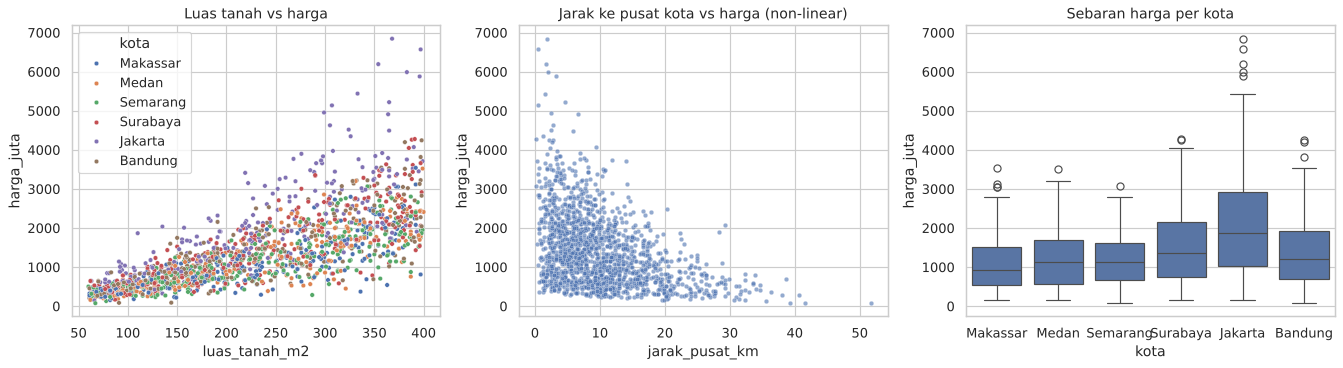

In [15]:
rng_r = np.random.default_rng(7)
N_r = 1500
faktor_kota = {'Jakarta': 1.8, 'Surabaya': 1.3, 'Bandung': 1.25, 'Medan': 1.05, 'Semarang': 1.0, 'Makassar': 0.95}
kota_r = rng_r.choice(list(faktor_kota), N_r)
luas_tanah = rng_r.uniform(60, 400, N_r).round()
luas_bangunan = (luas_tanah * rng_r.uniform(0.5, 1.4, N_r)).round()
jumlah_kamar = np.clip(np.round(luas_bangunan / 45 + rng_r.normal(0, 0.8, N_r)), 1, 7).astype(int)
jarak_pusat_km = rng_r.gamma(2.0, 5.0, N_r).round(1)
umur_bangunan = rng_r.integers(0, 35, N_r)

harga = (np.vectorize(faktor_kota.get)(kota_r)
         * (4.0 * luas_tanah + 2.8 * luas_bangunan + 30 * jumlah_kamar + 0.006 * luas_tanah ** 2)
         * np.exp(-jarak_pusat_km / 22) * (1 - 0.009 * umur_bangunan)
         * rng_r.lognormal(0, 0.07, N_r))

df_rumah = pd.DataFrame({'luas_tanah_m2': luas_tanah, 'luas_bangunan_m2': luas_bangunan,
                         'jumlah_kamar': jumlah_kamar, 'jarak_pusat_km': jarak_pusat_km,
                         'umur_bangunan_th': umur_bangunan, 'kota': kota_r, 'harga_juta': harga.round(1)})
display(df_rumah.head())
display(df_rumah.describe().T)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.scatterplot(data=df_rumah, x='luas_tanah_m2', y='harga_juta', hue='kota', s=15, ax=axes[0])
axes[0].set_title('Luas tanah vs harga')
sns.scatterplot(data=df_rumah, x='jarak_pusat_km', y='harga_juta', s=15, alpha=0.6, ax=axes[1])
axes[1].set_title('Jarak ke pusat kota vs harga (non-linear)')
sns.boxplot(data=df_rumah, x='kota', y='harga_juta', ax=axes[2])
axes[2].set_title('Sebaran harga per kota')
plt.tight_layout()
plt.show()

In [16]:
fitur_rumah_num = ['luas_tanah_m2', 'luas_bangunan_m2', 'jumlah_kamar', 'jarak_pusat_km', 'umur_bangunan_th']
Xr = df_rumah[fitur_rumah_num + ['kota']]
yr = df_rumah['harga_juta']
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.20, random_state=SEED)
print(f'Data latih: {len(Xr_train)} | Data uji: {len(Xr_test)}')

def prep_rumah():
    return ColumnTransformer([('num', StandardScaler(), fitur_rumah_num),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['kota'])])

model_regresi = {
    'Linear Regression': Pipeline([('prep', prep_rumah()), ('model', LinearRegression())]),
    'Polynomial Regression (derajat 2)': Pipeline([('prep', prep_rumah()),
                                                   ('poly', PolynomialFeatures(degree=2, include_bias=False)),
                                                   ('model', LinearRegression())]),
    'Support Vector Regression (RBF)': TransformedTargetRegressor(
        regressor=Pipeline([('prep', prep_rumah()), ('model', SVR(kernel='rbf', C=20, epsilon=0.02))]),
        transformer=StandardScaler()),
}

hasil_regresi, prediksi_regresi = {}, {}
for nama, model in model_regresi.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_test)
    prediksi_regresi[nama] = pred
    hasil_regresi[nama] = {
        'MAE (juta Rp)': mean_absolute_error(yr_test, pred),
        'MSE': mean_squared_error(yr_test, pred),
        'RMSE (juta Rp)': np.sqrt(mean_squared_error(yr_test, pred)),
        'R2': r2_score(yr_test, pred),
        'MAPE (%)': np.mean(np.abs((yr_test - pred) / yr_test)) * 100,
    }
tabel_regresi = pd.DataFrame(hasil_regresi).T.sort_values('R2', ascending=False)
print('\nPerbandingan performa regresi pada data uji:')
display(tabel_regresi.round(3))

Data latih: 1200 | Data uji: 300

Perbandingan performa regresi pada data uji:


,MAE (juta Rp),MSE,RMSE (juta Rp),R2,MAPE (%)
Support Vector Regression (RBF),97.557,"18,654.321",136.581,0.981,8.971
Polynomial Regression (derajat 2),101.723,"22,392.284",149.641,0.977,10.916
Linear Regression,230.866,"136,752.636",369.801,0.859,31.524


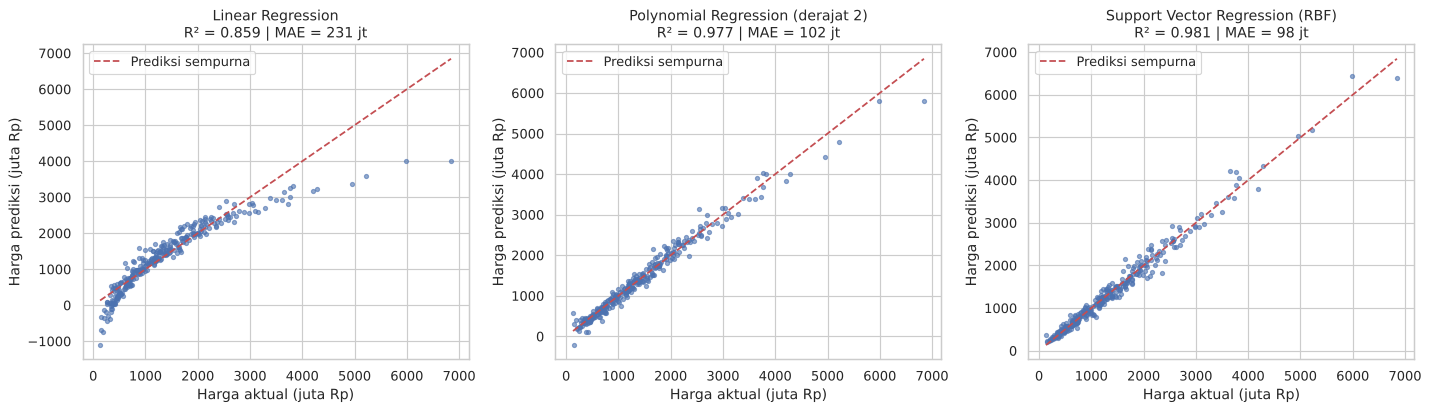

Estimasi nilai agunan rumah 150 m² / 120 m², 3 kamar, 8 km dari pusat Kota Bandung (Support Vector Regression (RBF)): Rp 954.6 juta


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
batas = [yr_test.min(), yr_test.max()]
for ax, (nama, pred) in zip(axes, prediksi_regresi.items()):
    ax.scatter(yr_test, pred, s=12, alpha=0.6)
    ax.plot(batas, batas, 'r--', label='Prediksi sempurna')
    ax.set_xlabel('Harga aktual (juta Rp)')
    ax.set_ylabel('Harga prediksi (juta Rp)')
    ax.set_title(f"{nama}\nR² = {hasil_regresi[nama]['R2']:.3f} | MAE = {hasil_regresi[nama]['MAE (juta Rp)']:.0f} jt")
    ax.legend()
plt.tight_layout()
plt.show()

reg_terbaik = tabel_regresi['R2'].idxmax()
RINGKASAN['Regresi nilai agunan'] = (f"{reg_terbaik}: R²={tabel_regresi.loc[reg_terbaik, 'R2']:.3f}, "
                                     f"MAE={tabel_regresi.loc[reg_terbaik, 'MAE (juta Rp)']:.1f} juta "
                                     f"(Linear R²={tabel_regresi.loc['Linear Regression', 'R2']:.3f})")

contoh_rumah = pd.DataFrame([{'luas_tanah_m2': 150, 'luas_bangunan_m2': 120, 'jumlah_kamar': 3,
                              'jarak_pusat_km': 8, 'umur_bangunan_th': 5, 'kota': 'Bandung'}])
print(f"Estimasi nilai agunan rumah 150 m² / 120 m², 3 kamar, 8 km dari pusat Kota Bandung "
      f"({reg_terbaik}): Rp {model_regresi[reg_terbaik].predict(contoh_rumah)[0]:,.1f} juta")

### 9.1 Analisis hasil regresi

1. **SVR (RBF) adalah model terbaik** dengan R² **0,981**, MAE **Rp97,6 juta**, dan MAPE **9,0%**, disusul *Polynomial Regression* derajat 2 (R² 0,977; MAPE 10,9%).
2. **Linear Regression tertinggal jauh** (R² 0,859; MAE Rp230,9 juta; MAPE 31,5%) karena hubungan harga dengan fitur bersifat non-linear: harga turun eksponensial terhadap jarak ke pusat kota dan efek kota bersifat perkalian. Model linear bahkan menghasilkan beberapa prediksi harga negatif, yang mustahil secara bisnis.
3. Penambahan fitur kuadrat dan interaksi pada *Polynomial Regression* sudah cukup untuk menangkap sebagian besar pola non-linear tersebut, sedangkan SVR dengan kernel RBF menangkapnya secara otomatis tanpa perlu merancang fitur tambahan.
4. Dengan MAPE ±9%, model SVR layak dipakai sebagai **penaksir awal** nilai agunan (contoh: rumah 150/120 m² di Bandung ditaksir ±Rp955 juta), sehingga *appraiser* dapat memfokuskan pemeriksaan lapangan pada properti dengan nilai besar atau karakteristik tidak biasa.

## 10. *Unsupervised Learning* — *Clustering* Segmentasi Nasabah

**Tujuan:** mengelompokkan nasabah berdasarkan perilaku transaksi **tanpa label**, sehingga Divisi Pemasaran dapat merancang promosi yang berbeda untuk setiap segmen.

Data simulasi berisi 2.000 nasabah dengan 10 fitur perilaku. Data dibangkitkan dari beberapa kelompok perilaku tersembunyi; label kelompok asli **tidak dipakai saat pelatihan** dan hanya disimpan untuk validasi akhir (hal yang hanya mungkin dilakukan pada data simulasi).

In [18]:
rng_c = np.random.default_rng(11)
profil_segmen = {   # (proporsi, usia, lama_nasabah, log_saldo, frek, nilai_trx, %digital, tarik_tunai, produk, limit_kk, utilisasi)
    'A': (0.15, (45, 8), (12, 4), (6.2, 0.5), (25, 8), (2500, 800), (60, 15), (3, 2), (5, 1), (60, 20), (20, 10)),
    'B': (0.35, (27, 4), (3, 2), (2.7, 0.5), (90, 20), (150, 50), (92, 5), (1, 1), (2.5, 1), (6, 3), (25, 10)),
    'C': (0.30, (55, 7), (18, 6), (4.8, 0.5), (8, 4), (600, 250), (20, 12), (8, 3), (2, 1), (2, 3), (10, 8)),
    'D': (0.20, (38, 6), (7, 3), (1.8, 0.5), (40, 12), (450, 150), (55, 12), (5, 2), (3, 1), (30, 8), (85, 8)),
}
N_c, baris = 2000, []
for seg, (prop, *param) in profil_segmen.items():
    n = int(prop * N_c)
    usia_c, lama_c, logsaldo, frek, nilai, digital, tarik, produk, limit, util = [rng_c.normal(m, s, n) for m, s in param]
    baris.append(pd.DataFrame({
        'usia': usia_c.clip(18, 75).round(), 'lama_nasabah_th': lama_c.clip(0.2, 40).round(1),
        'saldo_rata2_juta': np.exp(logsaldo).round(2), 'frekuensi_trx_bulan': frek.clip(1, None).round(),
        'nilai_trx_rata2_ribu': nilai.clip(10, None).round(), 'persen_trx_digital': digital.clip(0, 100).round(1),
        'tarik_tunai_bulan': tarik.clip(0, None).round(), 'jumlah_produk': produk.clip(1, 8).round(),
        'limit_kartu_kredit_juta': limit.clip(0, None).round(1), 'utilisasi_kredit_persen': util.clip(0, 100).round(1),
        'segmen_asli': seg}))
df_nasabah = pd.concat(baris, ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
fitur_cluster = [c for c in df_nasabah.columns if c != 'segmen_asli']
display(df_nasabah[fitur_cluster].describe().T)

# Saldo sangat menceng ke kanan -> transformasi log, lalu standardisasi
X_c = df_nasabah[fitur_cluster].copy()
X_c['saldo_rata2_juta'] = np.log1p(X_c['saldo_rata2_juta'])
X_c['nilai_trx_rata2_ribu'] = np.log1p(X_c['nilai_trx_rata2_ribu'])
X_c_scaled = StandardScaler().fit_transform(X_c)
print('Ukuran matriks fitur clustering:', X_c_scaled.shape)

,count,mean,std,min,25%,50%,75%,max
usia,"2,000.000",40.251,12.906,18.000,29.000,39.000,51.000,75.000
lama_nasabah_th,"2,000.000",9.499,7.273,0.200,3.600,7.400,14.300,35.200
saldo_rata2_juta,"2,000.000",135.790,235.128,1.070,10.010,25.670,147.630,"1,793.640"
frekuensi_trx_bulan,"2,000.000",46.336,38.237,1.000,11.000,35.000,80.000,155.000
nilai_trx_rata2_ribu,"2,000.000",694.301,846.130,10.000,173.750,416.500,722.250,"4,464.000"
persen_trx_digital,"2,000.000",58.200,30.550,0.000,31.875,59.400,89.300,100.000
tarik_tunai_bulan,"2,000.000",4.291,3.579,0.000,1.000,4.000,7.000,17.000
jumlah_produk,"2,000.000",2.861,1.372,1.000,2.000,3.000,4.000,8.000
limit_kartu_kredit_juta,"2,000.000",17.941,22.550,0.000,2.900,7.000,28.900,119.600
utilisasi_kredit_persen,"2,000.000",31.970,28.327,0.000,12.400,22.400,36.425,100.000


Ukuran matriks fitur clustering: (2000, 10)


### 10.1 Menentukan jumlah klaster optimal
Jumlah klaster *k* ditentukan dengan dua metode: **Elbow Method** (titik siku pada grafik inersia/WCSS) dan **Silhouette Score** (semakin mendekati 1, klaster semakin padat dan terpisah).

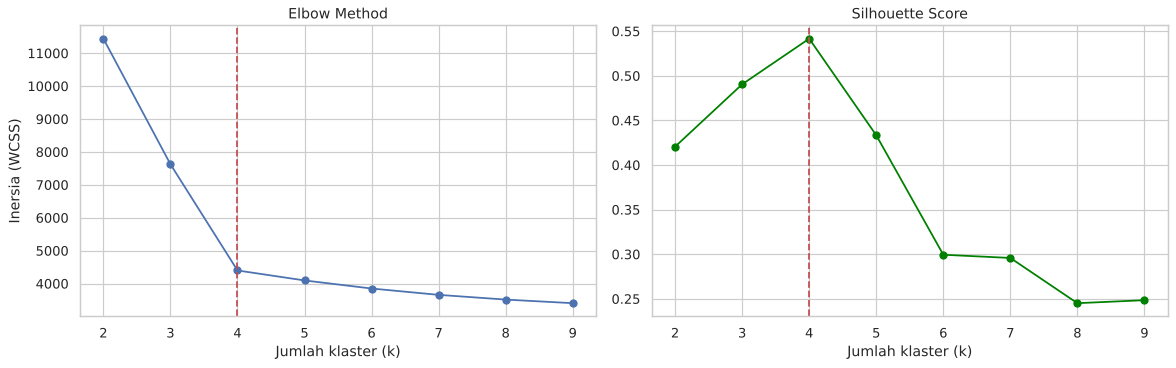

Silhouette per k: {2: np.float64(0.4205), 3: np.float64(0.4905), 4: np.float64(0.5416), 5: np.float64(0.4333), 6: np.float64(0.2994), 7: np.float64(0.2958), 8: np.float64(0.2451), 9: np.float64(0.2485)}
k optimal berdasarkan silhouette tertinggi: 4


In [19]:
rentang_k = range(2, 10)
inersia, silhouette = [], []
for k in rentang_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_c_scaled)
    inersia.append(km.inertia_)
    silhouette.append(silhouette_score(X_c_scaled, km.labels_))

k_optimal = list(rentang_k)[int(np.argmax(silhouette))]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(list(rentang_k), inersia, 'o-')
axes[0].axvline(k_optimal, color='r', ls='--')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Jumlah klaster (k)')
axes[0].set_ylabel('Inersia (WCSS)')
axes[1].plot(list(rentang_k), silhouette, 'o-', color='green')
axes[1].axvline(k_optimal, color='r', ls='--')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Jumlah klaster (k)')
plt.tight_layout()
plt.show()
print('Silhouette per k:', dict(zip(rentang_k, np.round(silhouette, 4))))
print(f'k optimal berdasarkan silhouette tertinggi: {k_optimal}')

### 10.2 K-Means dan profil setiap segmen

In [20]:
kmeans = KMeans(n_clusters=k_optimal, n_init=10, random_state=SEED).fit(X_c_scaled)
df_nasabah['klaster_kmeans'] = kmeans.labels_
profil = df_nasabah.groupby('klaster_kmeans')[fitur_cluster].median()
profil['jumlah_nasabah'] = df_nasabah['klaster_kmeans'].value_counts().sort_index()

# Penamaan segmen otomatis berdasarkan karakteristik paling menonjol
nama_segmen, sisa = {}, list(profil.index)
for kolom, nama in [('saldo_rata2_juta', 'Nasabah Prioritas'), ('utilisasi_kredit_persen', 'Pengguna Kredit Aktif'),
                    ('frekuensi_trx_bulan', 'Digital Aktif'), ('usia', 'Penabung Konservatif')]:
    if sisa:
        pilih = profil.loc[sisa, kolom].idxmax()
        nama_segmen[pilih] = nama
        sisa.remove(pilih)
for i in sisa:
    nama_segmen[i] = f'Segmen {i}'
df_nasabah['segmen'] = df_nasabah['klaster_kmeans'].map(nama_segmen)
urutan_segmen = sorted(df_nasabah['segmen'].unique())
warna_segmen = dict(zip(urutan_segmen, sns.color_palette('deep', len(urutan_segmen))))
profil.index = [nama_segmen[i] for i in profil.index]
print('Profil median setiap segmen:')
display(profil.round(1))

ari = adjusted_rand_score(df_nasabah['segmen_asli'], df_nasabah['klaster_kmeans'])
print(f'Silhouette K-Means = {silhouette_score(X_c_scaled, kmeans.labels_):.4f}')
print(f'Adjusted Rand Index terhadap segmen asli simulasi = {ari:.4f} (1 = identik sempurna)')

Profil median setiap segmen:


,usia,lama_nasabah_th,saldo_rata2_juta,frekuensi_trx_bulan,nilai_trx_rata2_ribu,persen_trx_digital,tarik_tunai_bulan,jumlah_produk,limit_kartu_kredit_juta,utilisasi_kredit_persen,jumlah_nasabah
Penabung Konservatif,54.000,17.400,118.800,8.000,603.000,20.400,8.000,2.000,2.000,9.900,601
Digital Aktif,27.000,3.000,15.000,92.000,152.000,91.900,1.000,3.000,6.200,25.000,700
Pengguna Kredit Aktif,38.000,6.800,6.000,40.000,448.000,56.400,5.000,3.000,30.200,84.800,400
Nasabah Prioritas,46.000,12.400,503.200,25.000,"2,468.000",59.100,3.000,5.000,61.000,21.100,299


Silhouette K-Means = 0.5416
Adjusted Rand Index terhadap segmen asli simulasi = 0.9989 (1 = identik sempurna)


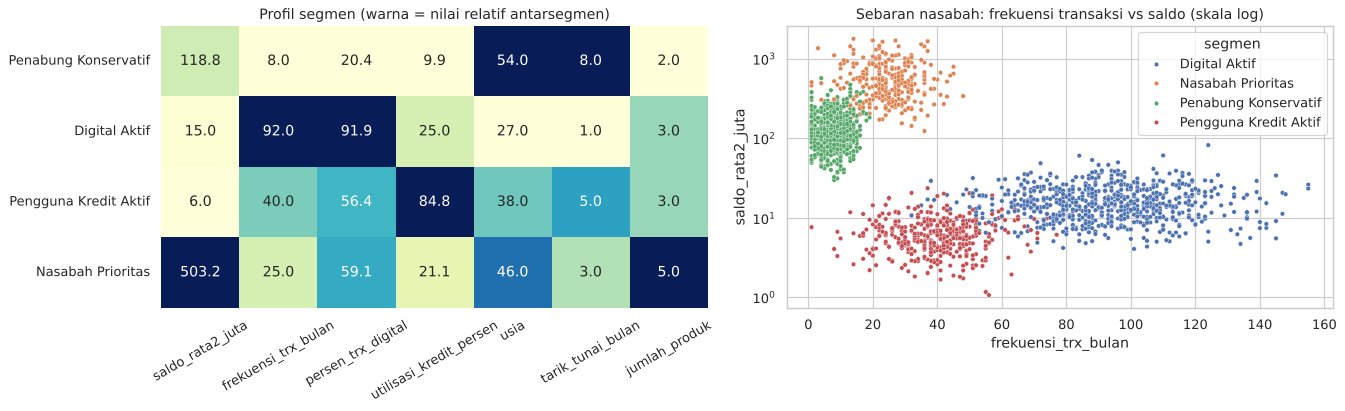

In [21]:
fitur_radar = ['saldo_rata2_juta', 'frekuensi_trx_bulan', 'persen_trx_digital', 'utilisasi_kredit_persen',
               'usia', 'tarik_tunai_bulan', 'jumlah_produk']
skala = profil[fitur_radar].copy()
skala = (skala - skala.min()) / (skala.max() - skala.min())
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(skala, annot=profil[fitur_radar].round(1), fmt='', cmap='YlGnBu', ax=axes[0], cbar=False)
axes[0].set_title('Profil segmen (warna = nilai relatif antarsegmen)')
axes[0].tick_params(axis='x', rotation=30)
sns.scatterplot(data=df_nasabah, x='frekuensi_trx_bulan', y='saldo_rata2_juta', hue='segmen', s=15, ax=axes[1],
                hue_order=urutan_segmen, palette=warna_segmen)
axes[1].set_yscale('log')
axes[1].set_title('Sebaran nasabah: frekuensi transaksi vs saldo (skala log)')
plt.tight_layout()
plt.show()

### 10.3 *Hierarchical Clustering* sebagai pembanding
*Hierarchical clustering* (metode Ward) membangun pohon penggabungan (*dendrogram*) sehingga struktur kelompok dapat dilihat secara bertingkat.

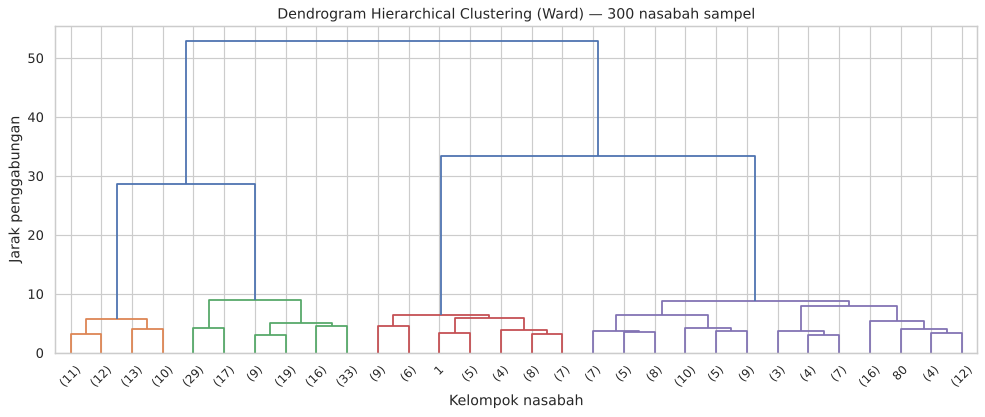

Silhouette Hierarchical = 0.5414
Kesesuaian Hierarchical vs K-Means (ARI) = 0.9989
Kesesuaian Hierarchical vs segmen asli (ARI) = 0.9977


In [22]:
idx_sampel = np.random.default_rng(SEED).choice(len(X_c_scaled), 300, replace=False)
Z = linkage(X_c_scaled[idx_sampel], method='ward')
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=30, ax=ax, color_threshold=Z[-(k_optimal - 1), 2])
ax.set_title('Dendrogram Hierarchical Clustering (Ward) — 300 nasabah sampel')
ax.set_xlabel('Kelompok nasabah')
ax.set_ylabel('Jarak penggabungan')
plt.show()

agglo = AgglomerativeClustering(n_clusters=k_optimal, linkage='ward').fit(X_c_scaled)
print(f'Silhouette Hierarchical = {silhouette_score(X_c_scaled, agglo.labels_):.4f}')
print(f'Kesesuaian Hierarchical vs K-Means (ARI) = {adjusted_rand_score(kmeans.labels_, agglo.labels_):.4f}')
print(f"Kesesuaian Hierarchical vs segmen asli (ARI) = {adjusted_rand_score(df_nasabah['segmen_asli'], agglo.labels_):.4f}")
RINGKASAN['Segmentasi nasabah'] = (f'K-Means k={k_optimal}, silhouette={silhouette_score(X_c_scaled, kmeans.labels_):.3f}, '
                                   f'ARI vs segmen asli={ari:.3f}')

### 10.4 Analisis hasil *clustering*

1. **Jumlah klaster optimal adalah 4.** *Silhouette score* tertinggi dicapai pada k = 4 (0,542), lebih baik daripada k = 3 (0,491) dan k = 5 (0,433). Grafik *elbow* juga melandai setelah k = 4.
2. **Empat segmen nasabah yang terbentuk:**

| Segmen | Jumlah | Karakteristik utama (median) | Strategi pemasaran |
|---|---|---|---|
| Digital Aktif | 700 | Usia 27 th, 92 transaksi/bulan, 92% transaksi digital, saldo ±Rp15 juta | Promo *cashback* QRIS/e-wallet, fitur aplikasi baru, paylater |
| Penabung Konservatif | 601 | Usia 54 th, saldo ±Rp119 juta, 8 transaksi/bulan, sering tarik tunai, digital 20% | Deposito, edukasi *mobile banking*, layanan kantor cabang |
| Pengguna Kredit Aktif | 400 | Utilisasi kartu kredit ±85%, limit ±Rp30 juta, saldo ±Rp6 juta | Program cicilan 0%, konsolidasi utang, pemantauan risiko gagal bayar |
| Nasabah Prioritas | 299 | Saldo ±Rp503 juta, nilai transaksi ±Rp2,5 juta, 5 produk, limit ±Rp61 juta | *Relationship manager*, reksa dana, asuransi, layanan prioritas |

3. **Hasil clustering sangat stabil.** *Hierarchical clustering* (Ward) menghasilkan pengelompokan yang hampir identik dengan K-Means (ARI 0,999) dengan silhouette yang sama (0,541). Karena data ini simulasi, hasil juga dapat dibandingkan dengan kelompok aslinya: ARI 0,999 menunjukkan K-Means berhasil menemukan kembali struktur tersembunyi tanpa pernah melihat label.
4. Transformasi log pada saldo dan nilai transaksi serta standardisasi fitur sangat penting, karena K-Means berbasis jarak Euclidean; tanpa itu, fitur saldo yang bernilai ratusan juta akan mendominasi perhitungan jarak.

## 11. *Unsupervised Learning* — Reduksi Dimensi (PCA & t-SNE)

Data segmentasi memiliki 10 fitur sehingga tidak dapat divisualisasikan langsung. **PCA** (*Principal Component Analysis*) memproyeksikan data ke sejumlah kecil komponen utama yang menyimpan variansi terbesar, sedangkan **t-SNE** adalah metode non-linear yang mempertahankan kedekatan lokal antardata dan sangat baik untuk visualisasi.

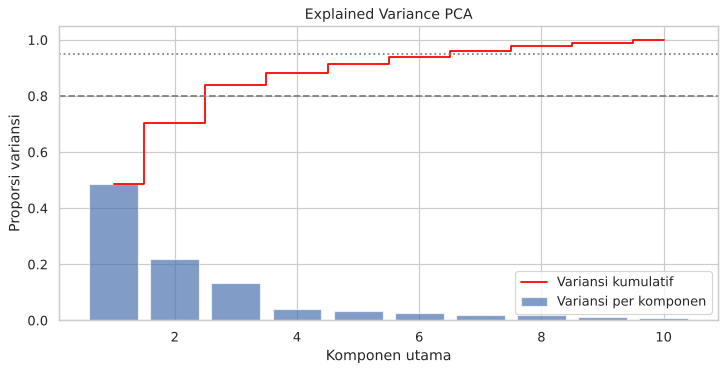

Proporsi variansi tiap komponen: [0.4861 0.2192 0.1345 0.0407 0.032  0.0259 0.0206 0.0178 0.013  0.0101]
PC1 + PC2 menjelaskan 70.5% variansi
Komponen yang dibutuhkan untuk 80% variansi: 3 | untuk 95% variansi: 7 (dari 10 fitur)

Loading (bobot fitur) pada PC1 dan PC2:


,PC1,PC2
usia,-0.406,-0.092
lama_nasabah_th,-0.387,-0.116
saldo_rata2_juta,-0.338,0.177
tarik_tunai_bulan,-0.330,-0.233
nilai_trx_rata2_ribu,-0.326,0.376
limit_kartu_kredit_juta,-0.083,0.601
jumlah_produk,-0.034,0.573
utilisasi_kredit_persen,0.143,0.170
persen_trx_digital,0.397,0.177
frekuensi_trx_bulan,0.412,-0.006


In [23]:
pca_full = PCA().fit(X_c_scaled)
var_kumulatif = np.cumsum(pca_full.explained_variance_ratio_)
n_95 = int(np.argmax(var_kumulatif >= 0.95) + 1)
n_80 = int(np.argmax(var_kumulatif >= 0.80) + 1)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(1, 11), pca_full.explained_variance_ratio_, alpha=0.7, label='Variansi per komponen')
ax.step(range(1, 11), var_kumulatif, where='mid', color='red', label='Variansi kumulatif')
ax.axhline(0.80, ls='--', color='gray')
ax.axhline(0.95, ls=':', color='gray')
ax.set_xlabel('Komponen utama')
ax.set_ylabel('Proporsi variansi')
ax.set_title('Explained Variance PCA')
ax.legend()
plt.show()

print('Proporsi variansi tiap komponen:', np.round(pca_full.explained_variance_ratio_, 4))
print(f'PC1 + PC2 menjelaskan {var_kumulatif[1]:.1%} variansi')
print(f'Komponen yang dibutuhkan untuk 80% variansi: {n_80} | untuk 95% variansi: {n_95} (dari 10 fitur)')

loading = pd.DataFrame(pca_full.components_[:2].T, index=fitur_cluster, columns=['PC1', 'PC2'])
print('\nLoading (bobot fitur) pada PC1 dan PC2:')
display(loading.round(3).sort_values('PC1'))

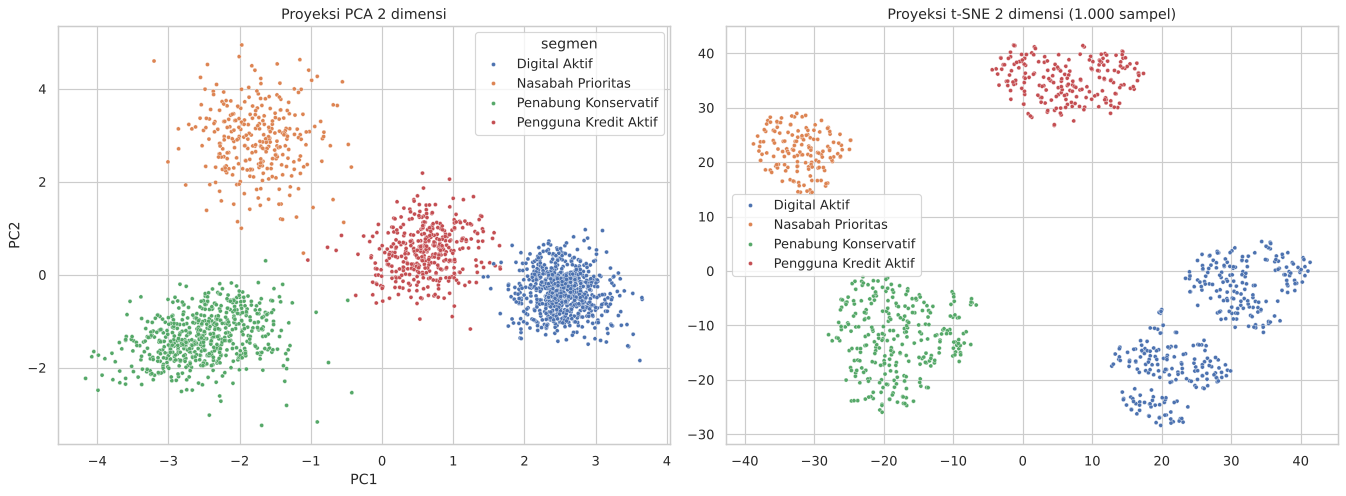

K-Means pada 3 komponen PCA -> ARI vs K-Means 10 fitur = 0.9989


In [24]:
X_pca2 = PCA(n_components=2, random_state=SEED).fit_transform(X_c_scaled)
idx_tsne = np.random.default_rng(SEED).choice(len(X_c_scaled), 1000, replace=False)
X_tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED).fit_transform(X_c_scaled[idx_tsne])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=X_pca2[:, 0], y=X_pca2[:, 1], hue=df_nasabah['segmen'], s=12, ax=axes[0],
                hue_order=urutan_segmen, palette=warna_segmen)
axes[0].set_title('Proyeksi PCA 2 dimensi')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=df_nasabah['segmen'].iloc[idx_tsne].values, s=12, ax=axes[1],
                hue_order=urutan_segmen, palette=warna_segmen)
axes[1].set_title('Proyeksi t-SNE 2 dimensi (1.000 sampel)')
plt.tight_layout()
plt.show()

# Pengaruh reduksi dimensi terhadap clustering
X_pca_k = PCA(n_components=n_80, random_state=SEED).fit_transform(X_c_scaled)
km_pca = KMeans(n_clusters=k_optimal, n_init=10, random_state=SEED).fit(X_pca_k)
print(f'K-Means pada {n_80} komponen PCA -> ARI vs K-Means 10 fitur = '
      f'{adjusted_rand_score(kmeans.labels_, km_pca.labels_):.4f}')
RINGKASAN['Reduksi dimensi'] = (f'PCA: 2 komponen = {var_kumulatif[1]:.1%} variansi; {n_80} komponen untuk 80%; '
                                f'{n_95} komponen untuk 95%')

### 11.1 Analisis hasil reduksi dimensi

1. **Dua komponen utama pertama menjelaskan 70,5% variansi** (PC1 48,6% dan PC2 21,9%). Hanya **3 komponen** yang dibutuhkan untuk menyimpan 80% informasi dan 7 komponen untuk 95%, dari total 10 fitur.
2. **Makna komponen** dapat dibaca dari *loading*:
   - **PC1** memisahkan nasabah senior yang konvensional (usia, lama menjadi nasabah, saldo, dan tarik tunai bernilai negatif) dari nasabah muda yang digital (frekuensi transaksi dan persentase transaksi digital bernilai positif). PC1 dapat ditafsirkan sebagai sumbu **"konvensional ↔ digital"**.
   - **PC2** didominasi limit kartu kredit, jumlah produk, dan nilai transaksi, sehingga dapat ditafsirkan sebagai **"kedalaman hubungan finansial dengan bank"**; segmen Nasabah Prioritas berada paling atas pada sumbu ini.
3. Pada proyeksi PCA, keempat segmen sudah terpisah cukup jelas. **t-SNE** memisahkan segmen lebih tegas karena mempertahankan kedekatan lokal secara non-linear, bahkan memperlihatkan sub-kelompok kecil di dalam segmen. Namun, jarak antarkelompok pada t-SNE tidak dapat ditafsirkan secara kuantitatif, sehingga t-SNE dipakai untuk visualisasi, sedangkan PCA dipakai untuk mengurangi fitur sebelum pemodelan.
4. K-Means yang dijalankan hanya pada **3 komponen PCA** menghasilkan klaster yang hampir sama dengan K-Means pada 10 fitur asli (ARI 0,999). Artinya, jumlah fitur dapat dikurangi lebih dari dua pertiga tanpa kehilangan informasi penting bagi segmentasi, sehingga komputasi menjadi lebih ringan.

## 12. *Unsupervised Learning* — Deteksi Anomali Transaksi (*Fraud Detection*)

**Tujuan:** menemukan transaksi kartu debit/kredit yang mencurigakan. Dalam praktik, transaksi *fraud* sangat jarang (umumnya < 2%) dan labelnya sering baru diketahui setelah nasabah melapor. Karena itu digunakan algoritma **deteksi anomali** yang dilatih **tanpa label**: model mempelajari pola transaksi normal, lalu menandai transaksi yang menyimpang.

Data simulasi berisi 5.000 transaksi dengan 1,5% transaksi *fraud*. Sebagian besar *fraud* bersifat mencolok (nominal besar, dini hari, lokasi jauh), tetapi sekitar seperempatnya adalah *fraud* "halus" yang meniru pola nasabah normal, sebagaimana sering terjadi di dunia nyata. Label *fraud* hanya dipakai untuk mengevaluasi hasil, bukan untuk melatih model.

In [25]:
rng_f = np.random.default_rng(21)
n_normal, n_fraud = 4925, 75

def buat_transaksi(n, fraud, halus=False):
    if not fraud:
        return pd.DataFrame({
            'nominal_rp': rng_f.lognormal(np.log(300_000), 0.9, n),
            'jam_transaksi': (rng_f.normal(13, 4, n) % 24),
            'jarak_dari_lokasi_biasa_km': rng_f.gamma(1.5, 2.0, n),
            'jumlah_trx_1_jam': rng_f.poisson(0.8, n) + 1,
            'rasio_thd_rata2_nasabah': rng_f.lognormal(0, 0.35, n),
            'merchant_baru': rng_f.binomial(1, 0.10, n),
            'is_fraud': 0, 'jenis': 'Normal'})
    if halus:   # fraud "halus": pelaku meniru pola transaksi nasabah sehingga sulit dibedakan
        return pd.DataFrame({
            'nominal_rp': rng_f.lognormal(np.log(900_000), 0.6, n),
            'jam_transaksi': rng_f.uniform(8, 22, n),
            'jarak_dari_lokasi_biasa_km': rng_f.gamma(2.0, 6.0, n),
            'jumlah_trx_1_jam': rng_f.poisson(1.5, n) + 1,
            'rasio_thd_rata2_nasabah': rng_f.lognormal(0.6, 0.4, n),
            'merchant_baru': rng_f.binomial(1, 0.4, n),
            'is_fraud': 1, 'jenis': 'Fraud halus'})
    return pd.DataFrame({
        'nominal_rp': rng_f.lognormal(np.log(4_500_000), 0.7, n),
        'jam_transaksi': np.where(rng_f.random(n) < 0.7, rng_f.uniform(0, 5, n), rng_f.uniform(0, 24, n)),
        'jarak_dari_lokasi_biasa_km': rng_f.gamma(2.5, 60, n),
        'jumlah_trx_1_jam': rng_f.poisson(4, n) + 1,
        'rasio_thd_rata2_nasabah': rng_f.lognormal(1.6, 0.5, n),
        'merchant_baru': rng_f.binomial(1, 0.75, n),
        'is_fraud': 1, 'jenis': 'Fraud mencolok'})

df_trx = pd.concat([buat_transaksi(n_normal, False), buat_transaksi(55, True),
                    buat_transaksi(n_fraud - 55, True, halus=True)], ignore_index=True)
df_trx = df_trx.sample(frac=1, random_state=SEED).reset_index(drop=True)
print(f"Total transaksi: {len(df_trx):,} | fraud: {df_trx['is_fraud'].sum()} ({df_trx['is_fraud'].mean():.2%})")
display(df_trx.drop(columns='is_fraud').groupby('jenis').median().round(2))

# Fitur untuk model (tanpa label). Fitur jam diubah ke bentuk siklik sin/cos agar jam 23 dekat dengan jam 0.
def fitur_anomali(d):
    return pd.DataFrame({
        'log_nominal': np.log(d['nominal_rp']),
        'jam_sin': np.sin(2 * np.pi * d['jam_transaksi'] / 24),
        'jam_cos': np.cos(2 * np.pi * d['jam_transaksi'] / 24),
        'log_jarak': np.log1p(d['jarak_dari_lokasi_biasa_km']),
        'jumlah_trx_1_jam': d['jumlah_trx_1_jam'],
        'log_rasio': np.log(d['rasio_thd_rata2_nasabah']),
        'merchant_baru': d['merchant_baru']})

X_f = StandardScaler().fit_transform(fitur_anomali(df_trx))
y_f = df_trx['is_fraud'].values

Total transaksi: 5,000 | fraud: 75 (1.50%)


,nominal_rp,jam_transaksi,jarak_dari_lokasi_biasa_km,jumlah_trx_1_jam,rasio_thd_rata2_nasabah,merchant_baru
jenis,,,,,,
Fraud halus,"796,890.960",16.850,8.900,2.000,1.550,0.000
Fraud mencolok,"5,277,032.540",3.790,140.420,5.000,5.190,1.000
Normal,"303,182.040",12.900,2.440,2.000,1.000,0.000


,Transaksi ditandai,Fraud tertangkap,Presisi,Recall,F1-Score
Isolation Forest,75.000,57.000,0.760,0.760,0.760
One-Class SVM,94.000,31.000,0.330,0.413,0.367


Proporsi transaksi yang ditandai anomali per jenis transaksi:


,Isolation Forest,One-Class SVM
jenis,,
Fraud halus,0.150,0.300
Fraud mencolok,0.982,0.455
Normal,0.004,0.013


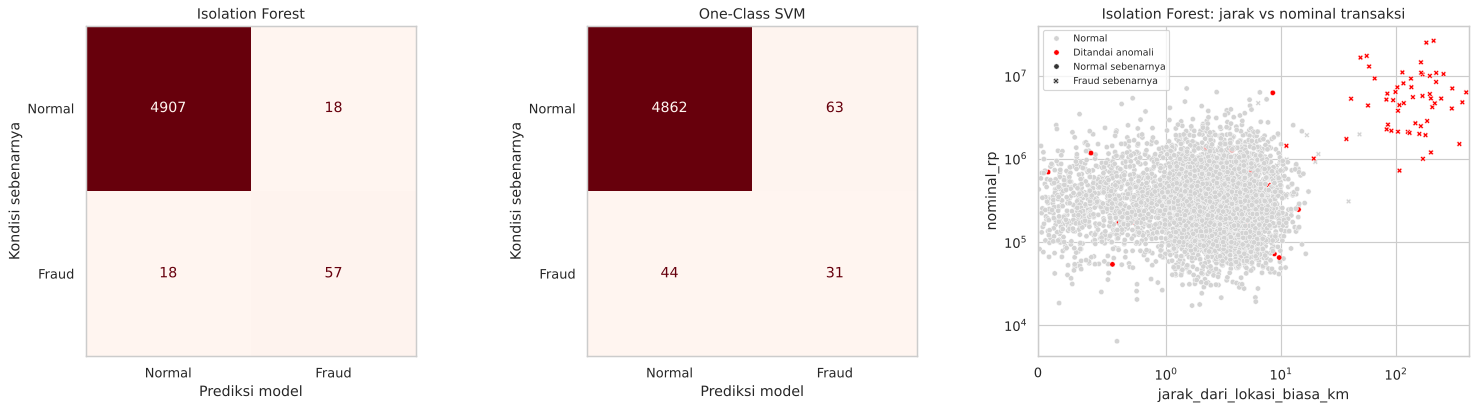

In [26]:
kontaminasi = 0.015
detektor = {
    'Isolation Forest': IsolationForest(n_estimators=300, contamination=kontaminasi, random_state=SEED),
    'One-Class SVM': OneClassSVM(kernel='rbf', nu=kontaminasi, gamma='scale'),
}
hasil_anomali, label_anomali = {}, {}
for nama, det in detektor.items():
    pred = (det.fit_predict(X_f) == -1).astype(int)          # -1 = anomali
    label_anomali[nama] = pred
    hasil_anomali[nama] = {'Transaksi ditandai': pred.sum(),
                           'Fraud tertangkap': int(((pred == 1) & (y_f == 1)).sum()),
                           'Presisi': precision_score(y_f, pred), 'Recall': recall_score(y_f, pred),
                           'F1-Score': f1_score(y_f, pred)}
tabel_anomali = pd.DataFrame(hasil_anomali).T
display(tabel_anomali.round(4))

print('Proporsi transaksi yang ditandai anomali per jenis transaksi:')
display(pd.DataFrame({n: pd.Series(p).groupby(df_trx['jenis']).mean() for n, p in label_anomali.items()}).round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nama, pred) in zip(axes[:2], label_anomali.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_f, pred), display_labels=['Normal', 'Fraud']).plot(
        ax=ax, cmap='Reds', colorbar=False)
    ax.set_title(nama)
    ax.grid(False)
    ax.set_xlabel('Prediksi model')
    ax.set_ylabel('Kondisi sebenarnya')
warna = np.where(label_anomali['Isolation Forest'] == 1, 'Ditandai anomali', 'Normal')
sns.scatterplot(x=df_trx['jarak_dari_lokasi_biasa_km'], y=df_trx['nominal_rp'], hue=warna,
                style=np.where(y_f == 1, 'Fraud sebenarnya', 'Normal sebenarnya'), s=20, ax=axes[2],
                palette={'Normal': 'lightgray', 'Ditandai anomali': 'red'})
axes[2].set_xscale('symlog', linthresh=1)
axes[2].set_xlim(0, None)
axes[2].set_yscale('log')
axes[2].set_title('Isolation Forest: jarak vs nominal transaksi')
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

det_terbaik = tabel_anomali['F1-Score'].astype(float).idxmax()
RINGKASAN['Deteksi fraud'] = (f"{det_terbaik}: recall={tabel_anomali.loc[det_terbaik, 'Recall']:.3f}, "
                              f"presisi={tabel_anomali.loc[det_terbaik, 'Presisi']:.3f} (tanpa label saat pelatihan)")

### 12.1 Analisis hasil deteksi anomali

1. **Isolation Forest jauh lebih unggul** daripada *One-Class SVM*. Dari 75 transaksi yang ditandai, 57 di antaranya benar-benar *fraud* (presisi dan *recall* **76%**), sedangkan hanya 18 dari 4.925 transaksi normal (0,4%) yang salah ditandai. *One-Class SVM* hanya menangkap 31 *fraud* (*recall* 41%) dengan presisi 33%.
2. **Rincian per jenis transaksi** menunjukkan bahwa Isolation Forest menangkap **98,2%** *fraud* mencolok (nominal besar, dini hari, lokasi jauh), tetapi hanya **15%** *fraud* halus yang meniru pola nasabah normal. Ini sesuai dengan cara kerja algoritma: Isolation Forest mengisolasi data yang "mudah dipisahkan" dari mayoritas, sehingga anomali yang menyerupai data normal sulit dikenali.
3. *One-Class SVM* sangat sensitif terhadap pemilihan parameter `gamma` dan `nu` serta bentuk sebaran data, sehingga pada data berdimensi campuran (biner, hitungan, dan kontinu) batas keputusannya kurang tepat.
4. **Implikasi bisnis:** model deteksi anomali cocok sebagai lapisan penyaring pertama yang bekerja tanpa label. Transaksi yang ditandai dapat ditahan sementara untuk verifikasi (misalnya OTP tambahan). Untuk menangkap *fraud* halus, bank perlu menambahkan fitur perilaku yang lebih kaya (misalnya perangkat, alamat IP, pola historis per nasabah) dan, setelah label *fraud* terkumpul, mengombinasikannya dengan model *supervised*.

## 13. *Unsupervised Learning* — *Association Rule Learning* untuk *Cross-Selling*

**Tujuan:** menemukan pola kepemilikan produk yang sering muncul bersamaan (*market basket analysis*), misalnya "nasabah yang memiliki Deposito cenderung juga memiliki Reksa Dana". Pola ini dipakai untuk menentukan produk apa yang ditawarkan kepada nasabah tertentu.

Algoritma **Apriori** diimplementasikan secara manual agar mekanismenya terlihat jelas. Tiga ukuran yang dihitung:
- **Support** = proporsi nasabah yang memiliki suatu kombinasi produk.
- **Confidence** (A → B) = peluang nasabah memiliki B jika ia memiliki A = support(A∪B) / support(A).
- **Lift** (A → B) = confidence / support(B). Lift > 1 berarti A dan B muncul bersama lebih sering daripada jika keduanya saling bebas.

Jumlah nasabah (transaksi): 4,000 | jumlah produk (item): 10


,Tabungan,Mobile Banking,E-Wallet Topup,Paylater,Kartu Kredit,Deposito,Reksa Dana,KPR,Asuransi Jiwa,Tabungan Pendidikan
0,1,0,0,0,0,0,0,0,0,0
1,1,0,1,0,1,0,0,0,0,0
2,1,0,1,1,0,0,1,1,0,1
3,1,1,0,1,1,0,0,0,0,0
4,1,1,1,1,0,0,0,0,0,0


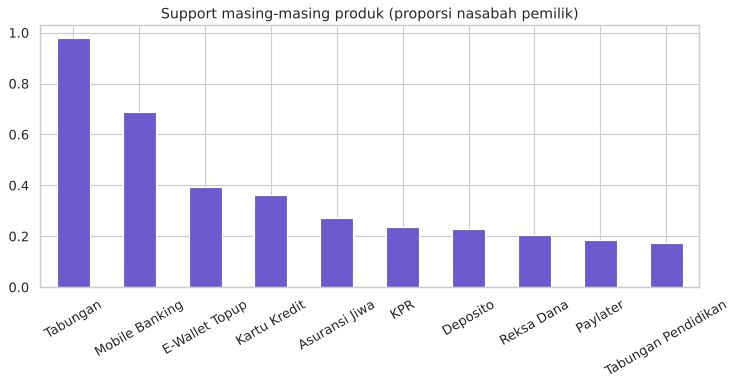

In [27]:
rng_a = np.random.default_rng(5)
N_a = 4000
tipe = rng_a.choice(['muda_digital', 'mapan', 'keluarga', 'umum'], N_a, p=[0.30, 0.20, 0.25, 0.25])
peluang = {   # peluang memiliki tiap produk per tipe nasabah
    'Tabungan':       {'muda_digital': .98, 'mapan': .99, 'keluarga': .98, 'umum': .97},
    'Mobile Banking': {'muda_digital': .95, 'mapan': .70, 'keluarga': .60, 'umum': .45},
    'E-Wallet Topup': {'muda_digital': .80, 'mapan': .20, 'keluarga': .25, 'umum': .15},
    'Paylater':       {'muda_digital': .45, 'mapan': .05, 'keluarga': .10, 'umum': .05},
    'Kartu Kredit':   {'muda_digital': .30, 'mapan': .75, 'keluarga': .35, 'umum': .15},
    'Deposito':       {'muda_digital': .03, 'mapan': .70, 'keluarga': .20, 'umum': .10},
    'Reksa Dana':     {'muda_digital': .15, 'mapan': .60, 'keluarga': .10, 'umum': .05},
    'KPR':            {'muda_digital': .02, 'mapan': .30, 'keluarga': .60, 'umum': .08},
    'Asuransi Jiwa':  {'muda_digital': .05, 'mapan': .45, 'keluarga': .55, 'umum': .10},
    'Tabungan Pendidikan': {'muda_digital': .01, 'mapan': .20, 'keluarga': .50, 'umum': .05},
}
keranjang = pd.DataFrame({produk: rng_a.random(N_a) < np.vectorize(p.get)(tipe) for produk, p in peluang.items()})
print(f'Jumlah nasabah (transaksi): {N_a:,} | jumlah produk (item): {keranjang.shape[1]}')
display(keranjang.head().astype(int))

fig, ax = plt.subplots(figsize=(10, 4))
keranjang.mean().sort_values(ascending=False).plot(kind='bar', ax=ax, color='slateblue', rot=30)
ax.set_title('Support masing-masing produk (proporsi nasabah pemilik)')
plt.show()

In [28]:
def apriori(data_bool, min_support):
    # Mencari semua itemset yang support-nya >= min_support secara bertahap (k = 1, 2, 3, ...).
    itemset_sering = {}
    kandidat = [frozenset([item]) for item in data_bool.columns]
    k = 1
    while kandidat:
        lolos = {}
        for c in kandidat:
            s = data_bool[list(c)].all(axis=1).mean()
            if s >= min_support:
                lolos[c] = s
        itemset_sering.update(lolos)
        k += 1
        kunci = list(lolos)
        # Prinsip Apriori: kandidat ukuran k hanya dibentuk dari itemset sering ukuran k-1
        kandidat = list({a | b for a in kunci for b in kunci if len(a | b) == k
                         and all(frozenset(s) in lolos for s in combinations(a | b, k - 1))})
    return itemset_sering

def buat_aturan(itemset_sering, min_confidence):
    aturan = []
    for itemset, sup in itemset_sering.items():
        if len(itemset) < 2:
            continue
        for r in range(1, len(itemset)):
            for anteseden in map(frozenset, combinations(itemset, r)):
                konsekuen = itemset - anteseden
                conf = sup / itemset_sering[anteseden]
                if conf >= min_confidence:
                    aturan.append({'Jika memiliki (A)': ', '.join(sorted(anteseden)),
                                   'Maka cenderung memiliki (B)': ', '.join(sorted(konsekuen)),
                                   'support': sup, 'confidence': conf,
                                   'lift': conf / itemset_sering[konsekuen]})
    return pd.DataFrame(aturan)

itemset_sering = apriori(keranjang, min_support=0.05)
print(f'Jumlah frequent itemset (support >= 5%): {len(itemset_sering)}')
def tanpa_tabungan(tabel):
    # Tabungan dimiliki ±98% nasabah sehingga hanya menghasilkan aturan duplikat yang tidak informatif
    ada = lambda teks: 'Tabungan' in teks.split(', ')
    return tabel[~tabel['Jika memiliki (A)'].map(ada) & ~tabel['Maka cenderung memiliki (B)'].map(ada)]

semua_aturan = tanpa_tabungan(buat_aturan(itemset_sering, min_confidence=0.3))
semua_aturan = semua_aturan[semua_aturan['lift'] > 1.2].sort_values(['lift', 'confidence'], ascending=False)
aturan = semua_aturan[semua_aturan['confidence'] >= 0.5].reset_index(drop=True)
print(f'Jumlah aturan dengan confidence >= 30% dan lift > 1,2 (untuk mesin rekomendasi): {len(semua_aturan)}')
print(f'Jumlah aturan kuat dengan confidence >= 50% dan lift > 1,2: {len(aturan)}\n')
print('15 aturan asosiasi terkuat:')
display(aturan.head(15).round(3))

Jumlah frequent itemset (support >= 5%): 108
Jumlah aturan dengan confidence >= 30% dan lift > 1,2 (untuk mesin rekomendasi): 55
Jumlah aturan kuat dengan confidence >= 50% dan lift > 1,2: 14

15 aturan asosiasi terkuat:


,Jika memiliki (A),Maka cenderung memiliki (B),support,confidence,lift
0,"Kartu Kredit, Reksa Dana",Deposito,0.065,0.558,2.430
1,"Deposito, Reksa Dana",Kartu Kredit,0.065,0.715,1.966
2,"KPR, Kartu Kredit",Asuransi Jiwa,0.054,0.528,1.936
3,Paylater,"E-Wallet Topup, Mobile Banking",0.112,0.601,1.880
4,Tabungan Pendidikan,Asuransi Jiwa,0.088,0.504,1.849
5,"Mobile Banking, Paylater",E-Wallet Topup,0.112,0.711,1.811
6,"Asuransi Jiwa, Deposito",Kartu Kredit,0.061,0.638,1.753
7,Paylater,E-Wallet Topup,0.122,0.654,1.667
8,"Deposito, Mobile Banking",Kartu Kredit,0.094,0.602,1.655
9,Deposito,Kartu Kredit,0.136,0.594,1.632


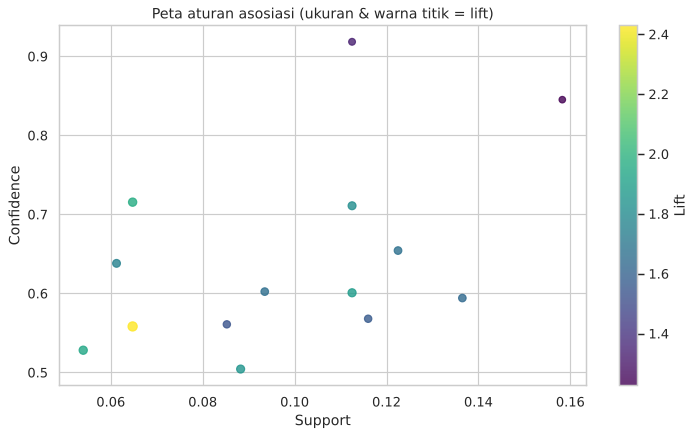

Nasabah memiliki: ['Tabungan', 'Deposito']


,Produk ditawarkan,confidence,lift,berdasarkan
0,Reksa Dana,0.394,1.929,Deposito
1,Kartu Kredit,0.594,1.632,Deposito
2,"Kartu Kredit, Mobile Banking",0.407,1.594,Deposito


Nasabah memiliki: ['Tabungan', 'KPR']


,Produk ditawarkan,confidence,lift,berdasarkan
0,Tabungan Pendidikan,0.360,2.059,KPR
1,Asuransi Jiwa,0.493,1.808,KPR
2,Deposito,0.343,1.494,KPR


Nasabah memiliki: ['Tabungan', 'Mobile Banking', 'E-Wallet Topup']


,Produk ditawarkan,confidence,lift,berdasarkan
0,Paylater,0.352,1.880,"E-Wallet Topup, Mobile Banking"


In [29]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sc = ax.scatter(aturan['support'], aturan['confidence'], c=aturan['lift'], s=aturan['lift'] * 25,
                cmap='viridis', alpha=0.8)
plt.colorbar(sc, label='Lift')
ax.set_xlabel('Support')
ax.set_ylabel('Confidence')
ax.set_title('Peta aturan asosiasi (ukuran & warna titik = lift)')
plt.show()

# Rekomendasi cross-selling untuk seorang nasabah berdasarkan aturan
def rekomendasi_produk(produk_dimiliki, tabel_aturan, top_n=3):
    dimiliki = set(produk_dimiliki)
    kandidat = []
    for _, r in tabel_aturan.iterrows():
        a = set(r['Jika memiliki (A)'].split(', '))
        b = set(r['Maka cenderung memiliki (B)'].split(', '))
        if a <= dimiliki and not (b & dimiliki):
            kandidat.append((r['Maka cenderung memiliki (B)'], r['confidence'], r['lift'], r['Jika memiliki (A)']))
    hasil = (pd.DataFrame(kandidat, columns=['Produk ditawarkan', 'confidence', 'lift', 'berdasarkan'])
             .sort_values(['lift', 'confidence'], ascending=False).drop_duplicates('Produk ditawarkan'))
    return hasil.head(top_n).reset_index(drop=True)

for profil_nasabah in [['Tabungan', 'Deposito'], ['Tabungan', 'KPR'], ['Tabungan', 'Mobile Banking', 'E-Wallet Topup']]:
    print(f'Nasabah memiliki: {profil_nasabah}')
    display(rekomendasi_produk(profil_nasabah, semua_aturan).round(3))

top = aturan.iloc[0]
RINGKASAN['Association rule'] = (f"{len(aturan)} aturan; terkuat: {{{top['Jika memiliki (A)']}}} -> "
                                 f"{{{top['Maka cenderung memiliki (B)']}}} (conf={top['confidence']:.2f}, lift={top['lift']:.2f})")

### 13.1 Analisis hasil *association rule*

1. Dari 4.000 nasabah ditemukan **108 *frequent itemset*** (support ≥ 5%), **55 aturan** dengan confidence ≥ 30% dan lift > 1,2, serta **14 aturan kuat** dengan confidence ≥ 50%. Produk Tabungan dikeluarkan dari aturan karena dimiliki hampir semua nasabah sehingga hanya menghasilkan aturan duplikat.
2. **Aturan paling kuat** dan maknanya:
   - {Kartu Kredit, Reksa Dana} → Deposito (confidence 55,8%, lift **2,43**): pemegang kartu kredit yang berinvestasi reksa dana 2,4 kali lebih mungkin memiliki deposito dibanding nasabah rata-rata. Kelompok ini adalah nasabah mapan.
   - {Deposito, Reksa Dana} → Kartu Kredit (confidence 71,5%, lift 1,97).
   - {KPR, Kartu Kredit} → Asuransi Jiwa (lift 1,94) dan Tabungan Pendidikan → Asuransi Jiwa (lift 1,85): pola nasabah keluarga.
   - Paylater → {E-Wallet Topup, Mobile Banking} (lift 1,88) dan {E-Wallet Topup, Paylater} → Mobile Banking (confidence 91,8%): pola nasabah muda digital.
3. **Mesin rekomendasi *cross-selling*** yang dibangun dari aturan tersebut menghasilkan penawaran yang masuk akal: pemilik Deposito ditawari Reksa Dana (lift 1,93) dan Kartu Kredit; pemilik KPR ditawari Tabungan Pendidikan (lift 2,06) dan Asuransi Jiwa (lift 1,81); nasabah digital ditawari Paylater (lift 1,88).
4. Aturan asosiasi menunjukkan **keterkaitan, bukan sebab-akibat**. Kepemilikan deposito tidak menyebabkan seseorang membuka kartu kredit; keduanya muncul bersama karena dimiliki oleh tipe nasabah yang sama. Oleh karena itu, hasil ini paling efektif bila dikombinasikan dengan segmentasi pada Bagian 10.

## 14. *Reinforcement Learning* — Navigasi Kendaraan Otonom Pengisi ATM

**Tujuan:** melatih **agen** (kendaraan otonom pengisi uang ATM) agar menemukan rute terbaik dari depot ke lokasi ATM pada peta kota berbentuk *grid* 7×7. Agen tidak diberi peta rute; ia belajar dari **coba-coba** (*trial and error*) melalui imbalan dan hukuman.

Komponen *reinforcement learning* pada kasus ini:

| Komponen | Implementasi |
|---|---|
| Agen | Kendaraan pengisi ATM |
| Lingkungan (*environment*) | Peta kota grid 7×7 |
| *State* | Posisi kendaraan (baris, kolom) |
| *Action* | Atas, bawah, kiri, kanan |
| *Reward* | +100 sampai di ATM, −1 setiap langkah (biaya bahan bakar/waktu), −15 memasuki ruas macet, −5 menabrak jalan ditutup/batas peta (posisi tidak berubah) |

Algoritma yang digunakan adalah **Q-Learning**, dengan aturan pembaruan:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\left[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\right]$$

dengan $\alpha$ = laju belajar, $\gamma$ = faktor diskon, dan strategi eksplorasi *ε-greedy* yang nilai ε-nya diturunkan bertahap.

In [30]:
PETA = [
    'S..#...',
    '.#.#.M.',
    '.#...#.',
    '.MM#.#.',
    '...#...',
    '#.##.M#',
    '..M...G',
]
BARIS, KOLOM = len(PETA), len(PETA[0])
AKSI = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}
PANAH = {0: '↑', 1: '↓', 2: '←', 3: '→'}
start = next((r, c) for r in range(BARIS) for c in range(KOLOM) if PETA[r][c] == 'S')
goal = next((r, c) for r in range(BARIS) for c in range(KOLOM) if PETA[r][c] == 'G')

def langkah(state, aksi):
    r, c = state
    dr, dc = AKSI[aksi]
    nr, nc = r + dr, c + dc
    if not (0 <= nr < BARIS and 0 <= nc < KOLOM) or PETA[nr][nc] == '#':
        return state, -5, False                 # menabrak, tetap di tempat
    if (nr, nc) == goal:
        return (nr, nc), 100, True
    if PETA[nr][nc] == 'M':
        return (nr, nc), -15, False             # ruas macet
    return (nr, nc), -1, False

def latih_q_learning(episode=2000, alpha=0.1, gamma=0.95, eps_awal=1.0, eps_min=0.01, peluruhan=0.997, seed=SEED):
    rng_rl = np.random.default_rng(seed)
    Q = np.zeros((BARIS, KOLOM, 4))
    eps, total_reward, jumlah_langkah = eps_awal, [], []
    for ep in range(episode):
        s, total, selesai, t = start, 0, False, 0
        while not selesai and t < 200:
            a = rng_rl.integers(4) if rng_rl.random() < eps else int(np.argmax(Q[s]))
            s2, r, selesai = langkah(s, a)
            target = r if selesai else r + gamma * np.max(Q[s2])
            Q[s][a] += alpha * (target - Q[s][a])
            s, total, t = s2, total + r, t + 1
        eps = max(eps_min, eps * peluruhan)
        total_reward.append(total)
        jumlah_langkah.append(t)
    return Q, total_reward, jumlah_langkah

Q, riwayat_reward, riwayat_langkah = latih_q_learning()
print(f'Rata-rata reward 100 episode pertama : {np.mean(riwayat_reward[:100]):8.1f}')
print(f'Rata-rata reward 100 episode terakhir: {np.mean(riwayat_reward[-100:]):8.1f}')
print(f'Rata-rata langkah 100 episode pertama : {np.mean(riwayat_langkah[:100]):6.1f}')
print(f'Rata-rata langkah 100 episode terakhir: {np.mean(riwayat_langkah[-100:]):6.1f}')

Rata-rata reward 100 episode pertama :   -309.6
Rata-rata reward 100 episode terakhir:     88.6
Rata-rata langkah 100 episode pertama :  108.2
Rata-rata langkah 100 episode terakhir:   12.1


Rute hasil belajar (12 langkah, total reward 89):
(0,0) -> (0,1) -> (0,2) -> (1,2) -> (2,2) -> (2,3) -> (2,4) -> (3,4) -> (4,4) -> (5,4) -> (6,4) -> (6,5) -> (6,6)
Ruas macet yang dilalui: 0


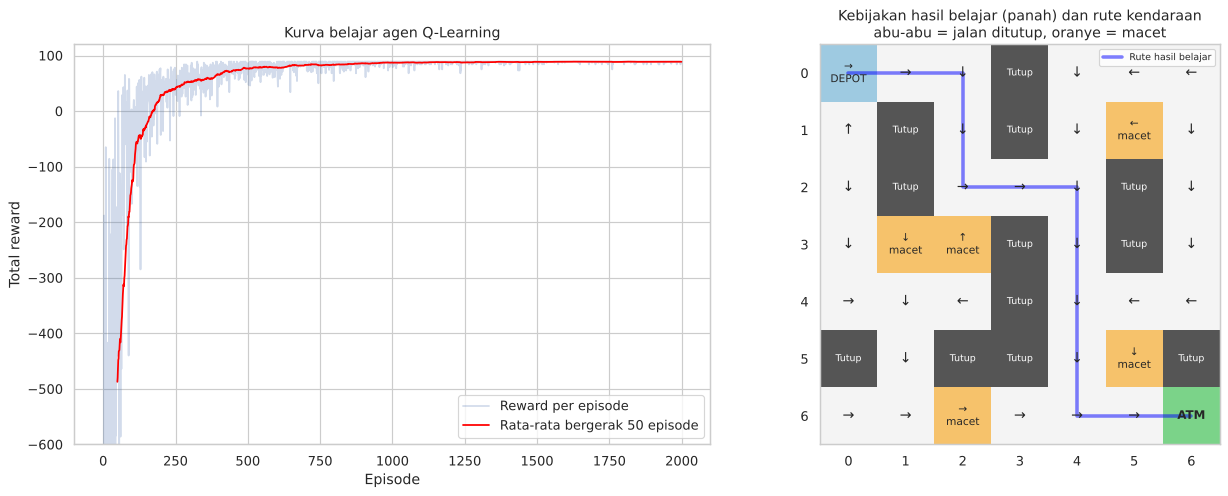

In [31]:
# Menjalankan kebijakan (policy) hasil belajar secara greedy
s, rute, total = start, [start], 0
for _ in range(50):
    s, r, selesai = langkah(s, int(np.argmax(Q[s])))
    rute.append(s)
    total += r
    if selesai:
        break
print(f'Rute hasil belajar ({len(rute) - 1} langkah, total reward {total}):')
print(' -> '.join(f'({r},{c})' for r, c in rute))
print(f"Ruas macet yang dilalui: {sum(PETA[r][c] == 'M' for r, c in rute)}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
jendela = 50
axes[0].plot(riwayat_reward, alpha=0.25, label='Reward per episode')
axes[0].plot(pd.Series(riwayat_reward).rolling(jendela).mean(), color='red', label=f'Rata-rata bergerak {jendela} episode')
axes[0].set_ylim(-600, 120)
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Total reward')
axes[0].set_title('Kurva belajar agen Q-Learning')
axes[0].legend()

from matplotlib.colors import ListedColormap
kode_sel = {'.': 0, 'M': 1, '#': 2, 'S': 3, 'G': 4}
grid = np.array([[kode_sel[ch] for ch in baris] for baris in PETA])
axes[1].imshow(grid, cmap=ListedColormap(['#f4f4f4', '#f6c26b', '#555555', '#9ecae1', '#7bd389']), vmin=-0.5, vmax=4.5)
axes[1].grid(False)
for r in range(BARIS):
    for c in range(KOLOM):
        ch = PETA[r][c]
        if ch == '#':
            axes[1].text(c, r, 'Tutup', ha='center', va='center', fontsize=8, color='white')
        elif ch == 'G':
            axes[1].text(c, r, 'ATM', ha='center', va='center', fontsize=10, weight='bold')
        else:
            label = PANAH[int(np.argmax(Q[r, c]))] + ('\nmacet' if ch == 'M' else '') + ('\nDEPOT' if ch == 'S' else '')
            axes[1].text(c, r, label, ha='center', va='center', fontsize=12 if ch == '.' else 9)
ry, rx = zip(*rute)
axes[1].plot(rx, ry, color='blue', lw=3, alpha=0.5, label='Rute hasil belajar')
axes[1].set_xticks(range(KOLOM))
axes[1].set_yticks(range(BARIS))
axes[1].set_title('Kebijakan hasil belajar (panah) dan rute kendaraan\nabu-abu = jalan ditutup, oranye = macet')
axes[1].legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()
RINGKASAN['Reinforcement learning'] = (f'Q-Learning: rute {len(rute) - 1} langkah, reward {total}; '
                                       f'rata-rata reward naik dari {np.mean(riwayat_reward[:100]):.0f} '
                                       f'menjadi {np.mean(riwayat_reward[-100:]):.0f}')

### 14.1 Analisis hasil *reinforcement learning*

1. **Agen berhasil belajar dari coba-coba.** Pada 100 episode pertama, rata-rata *reward* adalah **−309,6** dengan rata-rata **108 langkah** per episode, karena agen masih bergerak acak, sering menabrak jalan ditutup, dan masuk ke ruas macet. Pada 100 episode terakhir, rata-rata *reward* naik menjadi **88,6** dengan rata-rata **12,1 langkah**.
2. **Rute yang dipelajari adalah rute optimal.** Rute hasil belajar terdiri atas **12 langkah** dengan total *reward* **89** (100 − 11 biaya langkah) dan **tidak melewati satu pun ruas macet**. Karena jarak Manhattan dari depot (0,0) ke ATM (6,6) adalah 12, tidak ada rute yang lebih pendek; agen menemukan jalur terpendek sekaligus menghindari kemacetan tanpa pernah diberi peta.
3. Kurva belajar menunjukkan peralihan dari fase **eksplorasi** (ε tinggi, *reward* sangat bervariasi) ke fase **eksploitasi** (ε rendah, *reward* stabil mendekati maksimum) setelah sekitar 750 episode.
4. Panah pada peta menunjukkan **kebijakan (*policy*)** untuk setiap posisi, bukan hanya untuk rute utama. Jika kendaraan berada di posisi mana pun, misalnya setelah memutar balik, agen tetap mengetahui arah terbaik menuju ATM. Pada kondisi nyata, *state* dapat diperluas dengan kondisi lalu lintas waktu nyata sehingga agen menyesuaikan rute secara dinamis.

## 15. *Semi-Supervised Learning* — Kredit dengan Label Terbatas

**Skenario:** Divisi Kredit hanya mampu memverifikasi label (disetujui/ditolak) untuk **3% data latih** karena proses verifikasi mahal. Sisanya (97%) tidak berlabel. *Semi-supervised learning* memanfaatkan data berlabel yang sedikit **bersama** data tanpa label yang banyak.

Empat skenario dibandingkan pada data uji yang sama:
1. **Supervised (hanya 3% berlabel)** — data tanpa label dibuang.
2. **Self-Training** — model memberi label sementara (*pseudo-label*) pada data tanpa label yang prediksinya sangat yakin, lalu dilatih ulang secara berulang.
3. **Label Spreading** — label disebarkan ke data tetangga terdekat melalui graf kemiripan.
4. **Supervised (100% berlabel)** — batas atas (*upper bound*) sebagai pembanding.

Agar hasil tidak bergantung pada satu kali pengambilan sampel, eksperimen diulang 10 kali dengan subset berlabel yang berbeda.

Jumlah data berlabel: 71 dari 2,400 data latih (3.0%); sisanya 2,329 tidak berlabel



,Akurasi (rata-rata),Akurasi (std),F1 (rata-rata),F1 (std)
Supervised (3% berlabel),0.730,0.029,0.733,0.035
Self-Training,0.736,0.026,0.740,0.034
Label Spreading,0.660,0.023,0.704,0.020
Supervised (100% berlabel),0.787,0.000,0.793,0.000


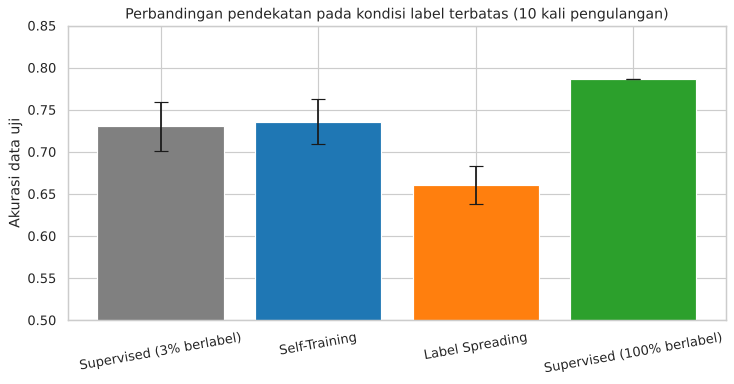

In [32]:
prep_ss = buat_preprocessor().fit(X_train)
Xs_train, Xs_test = prep_ss.transform(X_train), prep_ss.transform(X_test)
ytr = y_train.values
persen_label = 0.03

catatan = {k: [] for k in ['Supervised (3% berlabel)', 'Self-Training', 'Label Spreading', 'Supervised (100% berlabel)']}
for ulang in range(10):
    rng_s = np.random.default_rng(100 + ulang)
    idx_label = np.concatenate([rng_s.choice(np.where(ytr == kelas)[0], int(persen_label * (ytr == kelas).sum()),
                                             replace=False) for kelas in [0, 1]])
    y_sebagian = np.full_like(ytr, -1)          # -1 = tidak berlabel
    y_sebagian[idx_label] = ytr[idx_label]

    m1 = LogisticRegression(max_iter=2000).fit(Xs_train[idx_label], ytr[idx_label])
    m2 = SelfTrainingClassifier(LogisticRegression(max_iter=2000), threshold=0.80).fit(Xs_train, y_sebagian)
    m3 = LabelSpreading(kernel='knn', n_neighbors=15, alpha=0.2, max_iter=100).fit(Xs_train, y_sebagian)
    m4 = LogisticRegression(max_iter=2000).fit(Xs_train, ytr)
    for nama, m in zip(catatan, [m1, m2, m3, m4]):
        pred = m.predict(Xs_test)
        catatan[nama].append((accuracy_score(y_test, pred), f1_score(y_test, pred)))

print(f'Jumlah data berlabel: {len(idx_label)} dari {len(ytr):,} data latih '
      f'({len(idx_label) / len(ytr):.1%}); sisanya {len(ytr) - len(idx_label):,} tidak berlabel\n')
tabel_ss = pd.DataFrame({nama: {'Akurasi (rata-rata)': np.mean([a for a, f in v]),
                                'Akurasi (std)': np.std([a for a, f in v]),
                                'F1 (rata-rata)': np.mean([f for a, f in v]),
                                'F1 (std)': np.std([f for a, f in v])} for nama, v in catatan.items()}).T
display(tabel_ss.round(4))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(tabel_ss.index, tabel_ss['Akurasi (rata-rata)'], yerr=tabel_ss['Akurasi (std)'], capsize=6,
       color=['gray', 'tab:blue', 'tab:orange', 'tab:green'])
ax.set_ylim(0.5, 0.85)
ax.set_ylabel('Akurasi data uji')
ax.set_title('Perbandingan pendekatan pada kondisi label terbatas (10 kali pengulangan)')
ax.tick_params(axis='x', rotation=10)
plt.show()
RINGKASAN['Semi-supervised'] = ' | '.join(f"{n}: akurasi {r['Akurasi (rata-rata)']:.3f}" for n, r in tabel_ss.iterrows())

### 15.1 Analisis hasil *semi-supervised learning*

1. **Self-Training memberikan peningkatan kecil.** Dengan hanya 71 data berlabel (3%), model *supervised* mencapai akurasi **73,0%**, sedangkan *Self-Training* mencapai **73,6%** (F1 0,733 → 0,740). Peningkatan ini lebih kecil daripada simpangan baku antarpengulangan (±2,6–2,9%), sehingga belum dapat dianggap signifikan.
2. **Label Spreading justru menurunkan akurasi menjadi 66,0%.** Metode ini bergantung pada **asumsi klaster**, yaitu data yang berdekatan cenderung berlabel sama. Pada data kredit, pengajuan yang disetujui dan ditolak saling tumpang tindih di ruang fitur (terlihat pada histogram skor kredit dan rasio cicilan di Bagian 6.3), sehingga label yang disebarkan ke tetangga terdekat sering keliru.
3. **Nilai data berlabel tetap besar.** Selisih antara model dengan 3% label (73,0%) dan 100% label (78,7%) adalah 5,7 poin persentase. Pada kasus ini, menambah jumlah data berlabel lebih efektif daripada mengandalkan data tanpa label.
4. **Pelajaran penting:** *semi-supervised learning* bukan jaminan peningkatan performa. Metode ini efektif ketika data tanpa label memiliki struktur kelompok yang jelas dan selaras dengan label, seperti pada data teks dan gambar berskala besar, dan perlu diuji secara empiris sebelum diterapkan.

**Kaitan dengan *Large Language Models*:** prinsip memanfaatkan data tanpa label dalam jumlah sangat besar, lalu menyelaraskan model dengan sedikit data berlabel dan umpan balik manusia, adalah fondasi pelatihan LLM berbasis arsitektur *Transformer*. LLM terlebih dahulu dilatih pada korpus teks tanpa label berskala raksasa (*self-supervised pre-training*), kemudian disempurnakan dengan contoh berlabel (*supervised fine-tuning*) dan *Reinforcement Learning from Human Feedback* (RLHF) yang menggabungkan konsep Bagian 14 (agen, *reward*) dengan penilaian manusia.

## 16. Evaluasi Lanjutan: *Overfitting*, *Underfitting*, Validasi Silang, dan Analisis Residu

### 16.1 Mendeteksi *underfitting* dan *overfitting* melalui kompleksitas model
*Decision Tree* dilatih dengan kedalaman maksimum (`max_depth`) 1 sampai 25. Kedalaman kecil membuat model terlalu sederhana (*underfitting*), sedangkan kedalaman besar membuat model menghafal data latih (*overfitting*).

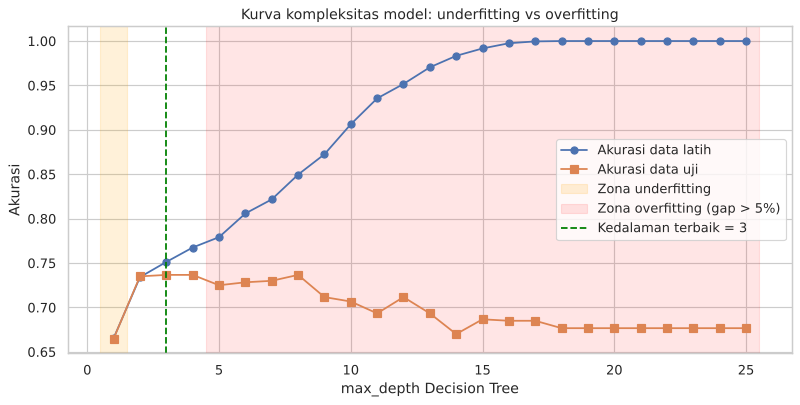

,max_depth,akurasi_latih,akurasi_uji,selisih (gap)
0,1,0.665,0.665,0.000
1,2,0.734,0.735,-0.001
2,3,0.751,0.737,0.015
4,5,0.779,0.725,0.054
9,10,0.906,0.707,0.200
14,15,0.992,0.687,0.305
24,25,1.000,0.677,0.323


In [33]:
kedalaman = list(range(1, 26))
skor_latih, skor_uji = [], []
for d in kedalaman:
    pipe = Pipeline([('prep', buat_preprocessor()), ('model', DecisionTreeClassifier(max_depth=d, random_state=SEED))])
    pipe.fit(X_train, y_train)
    skor_latih.append(accuracy_score(y_train, pipe.predict(X_train)))
    skor_uji.append(accuracy_score(y_test, pipe.predict(X_test)))

d_terbaik = kedalaman[int(np.argmax(skor_uji))]
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(kedalaman, skor_latih, 'o-', label='Akurasi data latih')
ax.plot(kedalaman, skor_uji, 's-', label='Akurasi data uji')
ax.axvspan(0.5, 1.5, color='orange', alpha=0.15, label='Zona underfitting')
awal_overfit = next(d for d, l, u in zip(kedalaman, skor_latih, skor_uji) if d > d_terbaik and l - u > 0.05)
ax.axvspan(awal_overfit - 0.5, 25.5, color='red', alpha=0.10, label='Zona overfitting (gap > 5%)')
ax.axvline(d_terbaik, color='green', ls='--', label=f'Kedalaman terbaik = {d_terbaik}')
ax.set_xlabel('max_depth Decision Tree')
ax.set_ylabel('Akurasi')
ax.set_title('Kurva kompleksitas model: underfitting vs overfitting')
ax.legend()
plt.show()

tabel_kompleksitas = pd.DataFrame({'max_depth': kedalaman, 'akurasi_latih': skor_latih, 'akurasi_uji': skor_uji})
tabel_kompleksitas['selisih (gap)'] = tabel_kompleksitas['akurasi_latih'] - tabel_kompleksitas['akurasi_uji']
display(tabel_kompleksitas[tabel_kompleksitas['max_depth'].isin([1, 2, d_terbaik, awal_overfit, 10, 15, 25])].round(4))

### 16.2 Validasi silang (*K-Fold Cross Validation*)
Satu kali pembagian data bisa menghasilkan skor yang kebetulan baik atau buruk. **Stratified 5-Fold Cross Validation** melatih dan menguji model lima kali pada lipatan data latih yang berbeda, sehingga diperoleh rata-rata dan simpangan baku performa. Ini sejalan dengan prinsip bahwa pengujian tidak cukup dilakukan sekali.

In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
hasil_cv = {}
for nama, model in model_klasifikasi.items():
    pipe = Pipeline([('prep', buat_preprocessor()), ('model', model)])
    skor = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy', 'f1'], return_train_score=True, n_jobs=-1)
    hasil_cv[nama] = {'Akurasi latih': skor['train_accuracy'].mean(),
                      'Akurasi validasi (rata-rata)': skor['test_accuracy'].mean(),
                      'Akurasi validasi (std)': skor['test_accuracy'].std(),
                      'F1 validasi (rata-rata)': skor['test_f1'].mean(),
                      'Gap latih-validasi': skor['train_accuracy'].mean() - skor['test_accuracy'].mean()}
tabel_cv = pd.DataFrame(hasil_cv).T.sort_values('F1 validasi (rata-rata)', ascending=False)
display(tabel_cv.round(4))

,Akurasi latih,Akurasi validasi (rata-rata),Akurasi validasi (std),F1 validasi (rata-rata),Gap latih-validasi
Logistic Regression,0.775,0.766,0.012,0.771,0.009
Random Forest,0.957,0.764,0.013,0.770,0.194
SVM (RBF),0.827,0.758,0.015,0.764,0.069
KNN (k=15),0.776,0.732,0.022,0.747,0.044
Decision Tree,0.793,0.733,0.024,0.734,0.060


### 16.3 *Hyperparameter tuning* dengan *Grid Search* dan *learning curve*

Kombinasi hyperparameter terbaik: {'model__max_depth': 6, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
F1 validasi silang terbaik : 0.7794
F1 data uji (model tuned)  : 0.7822
F1 data uji (RF default)   : 0.7858


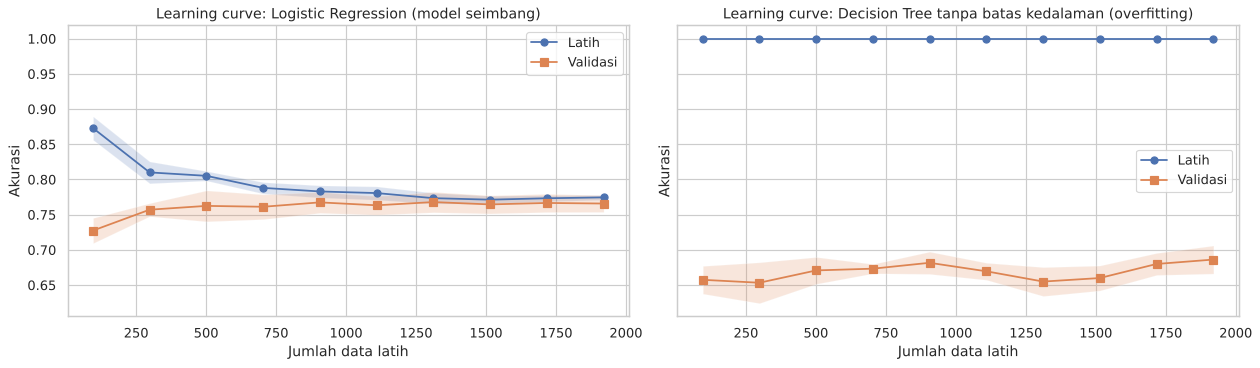

In [35]:
grid = GridSearchCV(
    Pipeline([('prep', buat_preprocessor()), ('model', RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
    param_grid={'model__n_estimators': [200, 400], 'model__max_depth': [6, 10, None],
                'model__min_samples_leaf': [1, 5, 10]},
    cv=cv, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)
print('Kombinasi hyperparameter terbaik:', grid.best_params_)
print(f'F1 validasi silang terbaik : {grid.best_score_:.4f}')
print(f'F1 data uji (model tuned)  : {f1_score(y_test, grid.predict(X_test)):.4f}')
print(f"F1 data uji (RF default)   : {hasil_klasifikasi['Random Forest']['F1-Score']:.4f}")

ukuran, latih_lc, val_lc = learning_curve(
    Pipeline([('prep', buat_preprocessor()), ('model', LogisticRegression(max_iter=2000))]),
    X_train, y_train, cv=cv, train_sizes=np.linspace(0.05, 1.0, 10), scoring='accuracy', n_jobs=-1)
ukuran2, latih_lc2, val_lc2 = learning_curve(
    Pipeline([('prep', buat_preprocessor()), ('model', DecisionTreeClassifier(random_state=SEED))]),
    X_train, y_train, cv=cv, train_sizes=np.linspace(0.05, 1.0, 10), scoring='accuracy', n_jobs=-1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (u, l, v, judul) in zip(axes, [(ukuran, latih_lc, val_lc, 'Logistic Regression (model seimbang)'),
                                       (ukuran2, latih_lc2, val_lc2, 'Decision Tree tanpa batas kedalaman (overfitting)')]):
    ax.plot(u, l.mean(1), 'o-', label='Latih')
    ax.fill_between(u, l.mean(1) - l.std(1), l.mean(1) + l.std(1), alpha=0.2)
    ax.plot(u, v.mean(1), 's-', label='Validasi')
    ax.fill_between(u, v.mean(1) - v.std(1), v.mean(1) + v.std(1), alpha=0.2)
    ax.set_title(f'Learning curve: {judul}')
    ax.set_xlabel('Jumlah data latih')
    ax.set_ylabel('Akurasi')
    ax.legend()
plt.tight_layout()
plt.show()

### 16.4 Analisis residu model regresi
Residu (selisih nilai aktual dan prediksi) yang baik seharusnya tersebar acak di sekitar nol tanpa pola. Pola sistematis pada residu menandakan model gagal menangkap sebagian hubungan pada data.

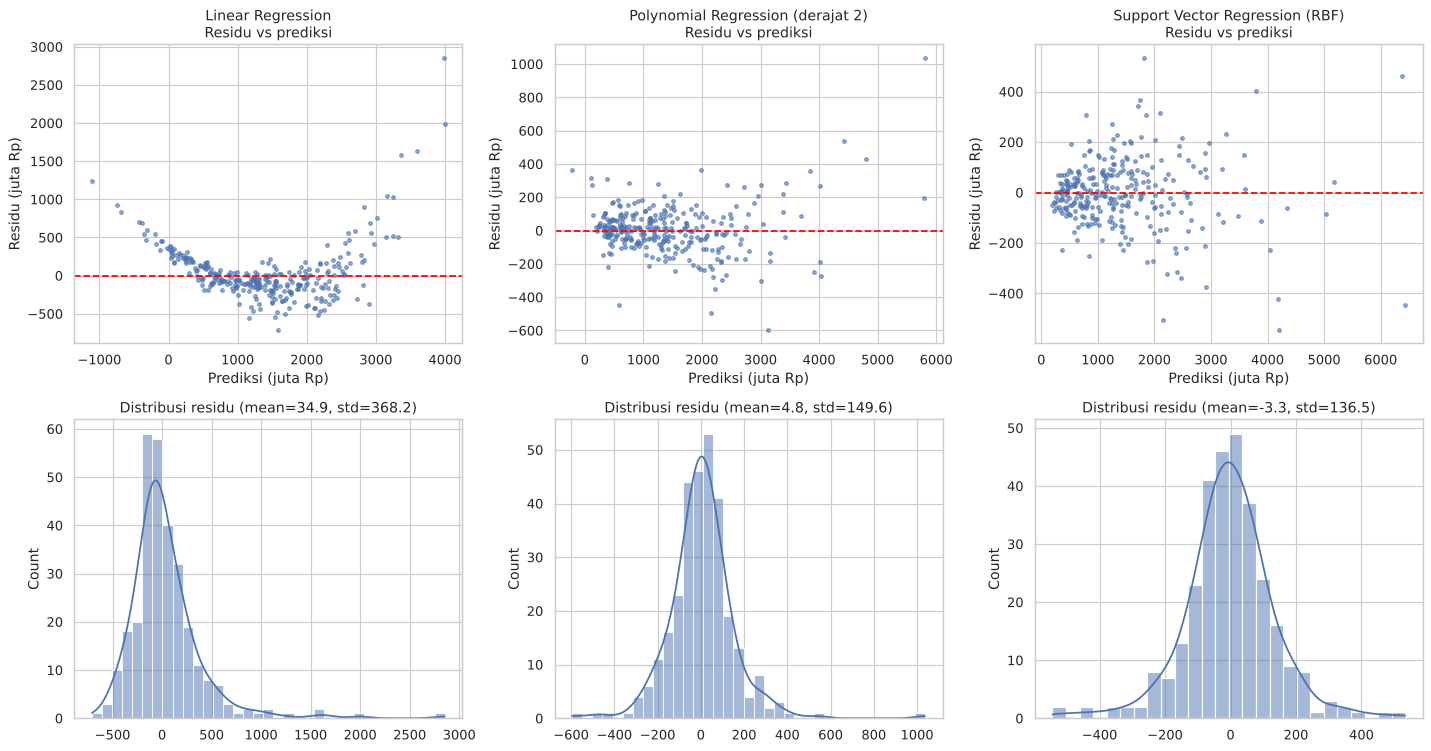

In [36]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for i, (nama, pred) in enumerate(prediksi_regresi.items()):
    residu = yr_test.values - pred
    axes[0, i].scatter(pred, residu, s=10, alpha=0.6)
    axes[0, i].axhline(0, color='red', ls='--')
    axes[0, i].set_title(f'{nama}\nResidu vs prediksi')
    axes[0, i].set_xlabel('Prediksi (juta Rp)')
    axes[0, i].set_ylabel('Residu (juta Rp)')
    sns.histplot(residu, kde=True, ax=axes[1, i])
    axes[1, i].set_title(f'Distribusi residu (mean={residu.mean():.1f}, std={residu.std():.1f})')
plt.tight_layout()
plt.show()

### 16.5 Analisis hasil evaluasi lanjutan

1. **Underfitting dan overfitting terlihat jelas pada kurva kompleksitas.** *Decision Tree* dengan kedalaman 1 hanya mencapai akurasi 66,5% baik pada data latih maupun data uji (*underfitting*: model terlalu sederhana). Kedalaman terbaik adalah **3** (akurasi uji 73,7%). Mulai kedalaman 5, selisih akurasi latih dan uji melebihi 5%, dan pada kedalaman 25 model mencapai akurasi latih **100%** tetapi akurasi uji turun ke **67,7%** (selisih 32,3 poin). Model tersebut menghafal data latih, termasuk *noise*-nya.
2. **Learning curve memperkuat temuan ini.** Pada *Logistic Regression*, kurva latih dan validasi bertemu di sekitar 77% seiring bertambahnya data, menandakan model yang seimbang. Pada *Decision Tree* tanpa batas kedalaman, akurasi latih selalu 100% sementara akurasi validasi tertahan di ±66–69%, yang merupakan ciri khas *overfitting*.
3. **Validasi silang 5-fold** mengonfirmasi peringkat model pada data uji: *Logistic Regression* memiliki akurasi validasi tertinggi (76,6% ± 1,2%) dengan selisih latih–validasi hanya 0,9 poin. *Random Forest* memiliki akurasi latih 95,7% (selisih 19,4 poin), tetapi akurasi validasinya tetap setara (76,4%) karena mekanisme *ensemble* meredam varians masing-masing pohon. Simpangan baku antar-*fold* yang kecil (1,2–2,4%) menunjukkan hasil yang stabil.
4. **Grid Search** memilih `max_depth=6`, `min_samples_leaf=1`, `n_estimators=200` dengan F1 validasi silang 0,779. F1 pada data uji (0,782) setara dengan model *default* (0,786), sehingga konfigurasi awal sudah mendekati optimal. *Tuning* tetap penting untuk memastikan hal tersebut secara sistematis, bukan berdasarkan tebakan.
5. **Analisis residu** menunjukkan pola berbentuk huruf U pada residu *Linear Regression*: model memperkirakan terlalu tinggi pada rentang harga menengah dan terlalu rendah pada harga sangat murah maupun sangat mahal. Ini bukti bahwa model linear gagal menangkap hubungan non-linear. Residu *Polynomial Regression* dan SVR tersebar acak di sekitar nol dengan simpangan baku yang jauh lebih kecil (±150 dan ±137 juta dibanding ±368 juta), menandakan pola penting pada data sudah tertangkap.

## 17. Ringkasan Hasil dan Kesimpulan

In [37]:
ringkasan = pd.DataFrame(list(RINGKASAN.items()), columns=['Kasus', 'Hasil utama'])
with pd.option_context('display.max_colwidth', None):
    display(ringkasan)

,Kasus,Hasil utama
0,Klasifikasi kredit,"Logistic Regression: F1=0.794, Akurasi=0.787 (rule-based F1=0.535)"
1,Regresi nilai agunan,"Support Vector Regression (RBF): R²=0.981, MAE=97.6 juta (Linear R²=0.859)"
2,Segmentasi nasabah,"K-Means k=4, silhouette=0.542, ARI vs segmen asli=0.999"
3,Reduksi dimensi,PCA: 2 komponen = 70.5% variansi; 3 komponen untuk 80%; 7 komponen untuk 95%
4,Deteksi fraud,"Isolation Forest: recall=0.760, presisi=0.760 (tanpa label saat pelatihan)"
5,Association rule,"14 aturan; terkuat: {Kartu Kredit, Reksa Dana} -> {Deposito} (conf=0.56, lift=2.43)"
6,Reinforcement learning,"Q-Learning: rute 12 langkah, reward 89; rata-rata reward naik dari -310 menjadi 89"
7,Semi-supervised,Supervised (3% berlabel): akurasi 0.730 | Self-Training: akurasi 0.736 | Label Spreading: akurasi 0.660 | Supervised (100% berlabel): akurasi 0.787


### Kesimpulan

1. **Pendekatan berbasis data terbukti lebih unggul daripada aturan manual.** Pada kasus persetujuan kredit, model *Logistic Regression* meningkatkan F1-score dari 0,535 (aturan manual) menjadi 0,794 dan mampu menangkap interaksi antarfaktor yang tidak dapat diakomodasi aturan if-else yang kaku.
2. **Alur kerja ML yang sistematis menentukan keberhasilan.** Pembersihan duplikat, penyeragaman kategori, penanganan nilai tidak valid, imputasi, *encoding*, standardisasi, rekayasa fitur (rasio cicilan menjadi fitur terpenting), serta pembagian data 80/20 dengan `Pipeline` untuk mencegah kebocoran data merupakan fondasi bagi seluruh model.
3. **Setiap kategori ML memiliki peran yang berbeda:**
   - *Supervised learning* untuk prediksi berlabel: klasifikasi kredit (akurasi 78,7%) dan regresi nilai agunan (SVR, R² 0,981, MAPE 9%).
   - *Unsupervised learning* untuk menemukan struktur tanpa label: 4 segmen nasabah (silhouette 0,542), reduksi 10 fitur menjadi 3 komponen PCA tanpa kehilangan struktur segmen, deteksi 98% *fraud* mencolok dengan Isolation Forest, dan 14 aturan *cross-selling* yang kuat.
   - *Reinforcement learning* untuk pengambilan keputusan berurutan: agen Q-Learning menemukan rute terpendek (12 langkah) yang menghindari seluruh ruas macet.
   - *Semi-supervised learning* hanya memberikan manfaat kecil pada data kredit karena kelas saling tumpang tindih, sehingga asumsi metode perlu diuji sebelum diterapkan.
4. **Algoritma yang lebih kompleks tidak otomatis lebih baik.** *Logistic Regression* mengungguli *Random Forest*, *SVM*, dan *KNN* pada klasifikasi kredit, sedangkan pada regresi agunan model non-linear jauh lebih baik. Pemilihan algoritma harus didasarkan pada karakteristik data, bukan popularitas algoritma.
5. **Evaluasi harus dilakukan berulang dan menyeluruh.** Kurva kompleksitas, *learning curve*, validasi silang, *grid search*, dan analisis residu berhasil mengungkap *underfitting* (akurasi 66,5% pada pohon kedalaman 1), *overfitting* (akurasi latih 100% vs uji 67,7%), dan pola non-linear yang terlewat oleh model linear. Pengujian satu kali tidak cukup untuk menjamin model andal di lingkungan produksi.
6. **Keterbatasan studi kasus:** data yang digunakan adalah data simulasi sehingga pola di dalamnya lebih bersih daripada data perbankan sesungguhnya. Pada penerapan nyata, model perlu divalidasi dengan data historis riil, dipantau secara berkala terhadap perubahan pola (*data drift*), diaudit agar tidak mendiskriminasi kelompok tertentu, serta dijelaskan alasan keputusannya kepada nasabah agar penggunaan AI tetap etis, aman, akuntabel, dan berkelanjutan.

### Referensi
1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
2. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer.
3. Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press.
4. Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation Forest. *Proceedings of the 8th IEEE International Conference on Data Mining*, 413–422.
5. Agrawal, R., & Srikant, R. (1994). Fast Algorithms for Mining Association Rules. *Proceedings of the 20th VLDB Conference*, 487–499.
6. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.